# PLA–ChAT spatial analysis · from raw HALO detections to scientific review
**Raw-data handoff edition · protocol 1.4.1 · research checked 19 October 2026**

### Open the Plotly app
**[Open the spatial app in your browser](http://127.0.0.1:8050/)** for the 3D, channel and layer controls plus the main scientific figures. First double-click `Launch_Spatial_Explorer.command` in this repository on your Mac, or run `python scripts/serve_spatial_app.py` in a terminal. Leave the terminal open while using the link. The app works from the saved results without running this notebook or installing extra packages.

You can also open the [portable app file](outputs/spatial_handoff/app/index.html) directly in a browser. In VS Code, open that file with your browser rather than the text editor. This is a saved snapshot; **Run All** refreshes it after the analysis completes. All core results remain in the notebook below.

This notebook reconstructs all **12 ChAT-panel sections** from the expanded dataset, using the new handoff to identify **six animals and their Running/Home-cage conditions**. It keeps **TDP43–HK1** and **TDP43–PFKP** separate. Every core result appears here: overlays, heat maps, interactive 3D views, quality review, animal-level findings and next experiments.

**What these images represent:** colored maps are computed from detected-object bounding-box midpoints. They are not recovered microscope photographs. The CSVs have no tissue-depth coordinate; the 3D views show **signal height over a 2D section**, with a slider to change animals. They do not reconstruct a brain volume or assume serial-section order.

**Start here:** [non-running minus Running](#comparison) → [machine learning](#machine-learning) → [interactive control center](#explore) → [experiment and inputs](#experiment) → [native overlays](#native) → [registration review](#registration) → [heat maps and zoom](#maps) → [interactive 3D](#three-d) → [animal-level findings](#findings) → [scientist action list](#actions).

The [main scientific notebook](PLA_ChAT_scientific_analysis.ipynb) starts with a compact findings summary, followed by comparisons, machine learning and interactive spatial views. This longer notebook retains the full audit, static figure collection and research methods. The [original exploratory notebook](PLA_ChAT_visual_analysis.ipynb) remains available for the historical box/outline analysis.

### Run and explore
1. **Read saved results without rerunning.** Open this notebook or the portable app. To recompute, follow [setup instructions](docs/quickstart.md), select the project Python kernel, then **Run All**. A fresh clone needs the raw CSVs supplied separately.
2. Use the **animal slider**, drag, hover and mouse-wheel zoom in the interactive figures. Static companion figures remain readable in GitHub and viewers that disable JavaScript. Trust a notebook only after reviewing its code; an untrusted notebook may suppress interactive outputs.
3. The notebook never waits for manual input during Run All. The optional review editor near the end needs a live kernel. Confirmed anatomical reviews are **not** pre-filled.

In [1]:
from pathlib import Path
import os, sys, importlib, json, warnings
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'bio_visuals').is_dir() and (p / 'requirements.txt').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the Bio_Data_Analysis repository.')
CACHE = ROOT / 'outputs' / '.cache' / 'matplotlib'
CACHE.mkdir(parents=True, exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(CACHE)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.io as pio
from IPython.display import display, Markdown, HTML, Image
# Reload in dependency order so a second Run All uses edited local functions.
for name in ['bio_visuals.data', 'bio_visuals.entire_dataset', 'bio_visuals.handoff', 'bio_visuals.handoff_plots', 'bio_visuals.explorer', 'bio_visuals.condition_comparison', 'bio_visuals.condition_views', 'bio_visuals.condition_layout', 'bio_visuals.normalization', 'bio_visuals.feature_alignment', 'bio_visuals.morphology_ml', 'bio_visuals.morphology_views', 'bio_visuals.standalone_app']:
    importlib.reload(importlib.import_module(name))
from bio_visuals import entire_dataset as raw, handoff as h, handoff_plots as hp
from bio_visuals.explorer import explorer_html
from bio_visuals import condition_comparison as cc, condition_views as cv, condition_layout as cl
from bio_visuals import normalization as norm, feature_alignment as fa
from bio_visuals import morphology_ml as ml, morphology_views as mv
from bio_visuals.standalone_app import write_standalone_app
hp.style()
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
DATA = ROOT / 'entire Chat dataset'
OUT = ROOT / 'outputs' / 'spatial_handoff'
TABLES = OUT / 'tables'
ARRAYS = OUT / 'spatial_arrays'
for directory in (OUT, TABLES, ARRAYS): directory.mkdir(parents=True, exist_ok=True)
REVIEW_PATH = ROOT / 'metadata' / 'handoff_section_reviews.json'
EXPORT_OBJECT_TABLES = False  # Optional large, lossless per-object handoff; raw files remain unchanged.
SHOW_REVIEW_EDITOR = False    # Set True only when conducting an actual geometry review.
PARAMETERS = dict(h.PARAMETERS)

def show(fig, name):
    saved = hp.save(fig, OUT, name)
    # Explicit PNG embedding works with Agg, VS Code, Jupyter and static GitHub previews.
    # Display width changes layout only; the complete 300-DPI image stays embedded.
    display(Image(filename=str(saved), embed=True, width=1100))
    plt.close(fig)

def table(frame, name):
    frame.to_csv(TABLES / (name + '.csv.gz'), index=False, compression='gzip')
    display(frame)

# Embedded JS supports offline classic notebooks; MIME supports JupyterLab/VS Code.
pio.renderers.default = 'plotly_mimetype+notebook'
PLOT_CONFIG = {'scrollZoom': True, 'displaylogo': False,
               'toImageButtonOptions': {'format': 'png', 'scale': 3}}
print('Repository:', ROOT)
print('Python:', sys.executable)
print('Inputs:', DATA)

Repository: /Users/adambrewer/Desktop/Coding/Bio_Data_Analysis
Python: /Users/adambrewer/Desktop/Coding/Bio_Data_Analysis/.venv/bin/python
Inputs: /Users/adambrewer/Desktop/Coding/Bio_Data_Analysis/entire Chat dataset


<a id="experiment"></a>
## 1 · What was measured, and what question can it answer?

The handoff describes coronal brain sections from Running animals **22F, 21M, 22M** and Home-cage animals **21F, 23M, 24M**. Each animal contributes one HK1-arm section and a **different physical section** for the PFKP arm. The ChAT marker is measured alongside PLA. The handoff supplies these identities; the filename suffixes alone are not used to infer sex, age, species, genotype or treatment details. [Local handoff, pp. 1–3 and 8](HALO_spatial_analysis_raw_data_handoff.pdf).

The scientific question is: **how is each PLA proximity signal distributed relative to ChAT-positive structures, and does that association differ between Running and Home-cage animals?** PLA measures target proximity under the assay conditions. ChAT overlap locates that signal relative to a detected cholinergic marker compartment; it is not a count of neurons, a direct-binding assay, or a glycolytic-flux measurement. [Söderberg et al., 2006](https://www.nature.com/articles/nmeth947), [Dunn et al., 2011](https://pubmed.ncbi.nlm.nih.gov/21209361/).

| Available now | Needed for stronger spatial biology |
|---|---|
| Raw object coordinates, bounding boxes, area in µm², intensity, ChAT-presence flag and overlap measurements | Original fluorescence channels, HALO ROI/segmentation polygons and detection settings |
| Animal assignments and two separate PLA arms | Reviewed cavity polygons, discrete flips and tissue-support QC |
| Three source-image references; 12 completed sections | Confirmed coordinate scale, imaging batches, section level and experiment/control metadata |
| ChAT-panel exports only | Other marker panels before cross-marker PCA or synaptic/metabolic state-space analysis |

**A handoff caveat that does not apply to this folder:** the missing 21M HK1-arm section and duplicated 23M PFKP export discussed on p. 3 concern the **high-contrast HK1 marker panel**. That panel is absent here. The ChAT 21M/HK1 section is present (job 5006). The interrupted ChAT job 4978 is a different, explicitly audited replacement event.

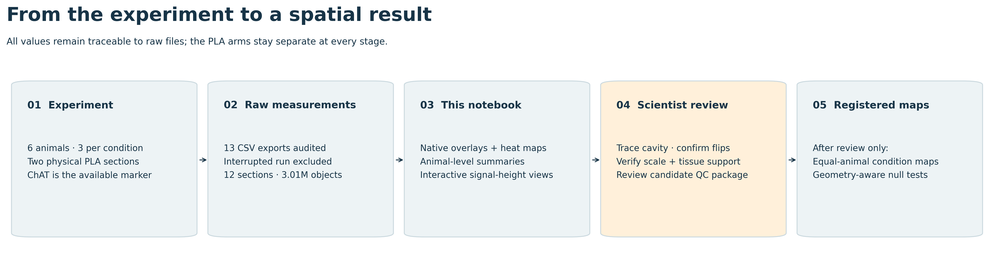

In [2]:
show(hp.workflow_figure(), '01_workflow')

## 2 · Load every CSV and establish provenance

Read all 13 files fresh, validate all rows, hash inputs and keep 12 primary exports. Do not reuse a previously aligned coordinate table. Job 4978 is superseded by 5403; the four byte-identical `Initial Data/` outline copies are audited but not concatenated. Object identity is **source file + Object Id**, never Object Id alone. Native x/y are bounding-box midpoints, not segmentation centroids.

In [3]:
objects, manifest = raw.load_complete_dataset(DATA, verify_hashes=True)
metadata = h.section_metadata(manifest)
summary = h.animal_summary(objects, metadata)
copies = raw.compare_initial_files(manifest, ROOT / 'Initial Data')
# Verify the interrupted/replacement relationship against every measurement field.
m = manifest.set_index('job')
short = raw.load_export(DATA / m.loc['4978', 'source_file'], m.loc['4978'].to_dict() | {'job':'4978'})
full = objects[objects.job == '5403']
repeat_audit = pd.DataFrame([raw.signature_overlap(short, full)])
del short, full
assert copies.identical_file.all()
assert repeat_audit.short_unmatched_rows.iloc[0] == 0
assert len(objects) == int(manifest.loc[manifest.is_primary, 'rows'].sum())
manifest.to_csv(TABLES / 'input_manifest.csv.gz', index=False, compression='gzip')
metadata.to_csv(TABLES / 'section_metadata.csv.gz', index=False, compression='gzip')
copies.to_csv(TABLES / 'initial_copy_audit.csv.gz', index=False, compression='gzip')
summary.to_csv(TABLES / 'animal_summary.csv.gz', index=False, compression='gzip')
display(Markdown(f'**Loaded {len(manifest)} exports; retained {len(metadata)} distinct sections and {len(objects):,} objects.** '
                 f'{sum(objects.object_type == "PLA"):,} PLA; {sum(objects.object_type == "ChAT"):,} ChAT. '
                 f'{len(copies)} original outline files are exact copies.'))
table(repeat_audit, 'interrupted_repeat_audit')
display(metadata[['job','animal_id','running_group','pla_arm','rows','image_label','marker_panel']])

**Loaded 13 exports; retained 12 distinct sections and 3,010,776 objects.** 310,024 PLA; 2,700,752 ChAT. 4 original outline files are exact copies.

,short_rows,full_rows,identical_measurement_rows,short_unmatched_rows,full_additional_rows
0,94409,190915,94409,0,96506


,job,animal_id,running_group,pla_arm,rows,image_label,marker_panel
0,4998,21F,Home cage,TDP43–HK1,323082,Image 1,ChAT
1,5006,21M,Running,TDP43–HK1,176423,Image 3,ChAT
2,4997,22F,Running,TDP43–HK1,163549,Image 1,ChAT
3,5001,22M,Running,TDP43–HK1,237144,Image 2,ChAT
4,5007,23M,Home cage,TDP43–HK1,306291,Image 3,ChAT
5,5002,24M,Home cage,TDP43–HK1,349776,Image 2,ChAT
6,5020,21F,Home cage,TDP43–PFKP,240702,Image 1,ChAT
7,5003,21M,Running,TDP43–PFKP,193552,Image 3,ChAT
8,5403,22F,Running,TDP43–PFKP,190915,Image 1,ChAT
9,4999,22M,Running,TDP43–PFKP,184684,Image 2,ChAT


In [4]:
qc_columns = ['job','is_primary','duplicate_ids','missing_values','nonpositive_area',
              'overlap_presence_mismatch','overlap_pct_formula_mismatch','any_zero_diameter',
              'zero_bbox_width_or_height','diameter_order_mismatch']
table(manifest[qc_columns], 'measurement_qc')
# Image labels are acquisition references, not additional biological replicates.
table(metadata.groupby(['image_label','pla_arm','running_group'], observed=True).size()
      .rename('sections').reset_index(), 'image_group_balance')

,job,is_primary,duplicate_ids,missing_values,nonpositive_area,overlap_presence_mismatch,overlap_pct_formula_mismatch,any_zero_diameter,zero_bbox_width_or_height,diameter_order_mismatch
0,4998,True,0,0,0,0,0,10405,9422,0
1,5020,True,0,0,0,0,0,7255,6705,0
2,4997,True,0,0,0,0,0,3472,3438,0
3,4978,False,0,0,0,0,0,1185,1267,0
4,5403,True,0,0,0,0,0,2448,2521,0
5,5001,True,0,0,0,0,0,4143,4007,0
6,4999,True,0,0,0,0,0,2291,2136,0
7,5002,True,0,0,0,0,0,13493,12222,0
8,5000,True,0,0,0,0,0,2360,1926,0
9,5006,True,0,0,0,0,0,6481,6060,0


,image_label,pla_arm,running_group,sections
0,Image 1,TDP43–HK1,Home cage,1
1,Image 1,TDP43–HK1,Running,1
2,Image 1,TDP43–PFKP,Home cage,1
3,Image 1,TDP43–PFKP,Running,1
4,Image 2,TDP43–HK1,Home cage,1
5,Image 2,TDP43–HK1,Running,1
6,Image 2,TDP43–PFKP,Home cage,1
7,Image 2,TDP43–PFKP,Running,1
8,Image 3,TDP43–HK1,Home cage,1
9,Image 3,TDP43–HK1,Running,1


**How to read QC:** zero diameters and degenerate boxes are reported, not silently removed. Area/flag definitions come from the export and require original-image review before assigning biological meaning. A valid numerical row can still be a segmentation artifact. Source-image references appear in both conditions; that does not establish matched acquisition settings, randomization or complete batch control.

Coordinate headers do not establish pixels or µm. All spatial axes therefore remain in **HALO export units**. Area and diameter retain the physical units explicitly named in their column headers; those units are not used to invent an x/y calibration. No object-area sum is treated as sampled tissue area.

In [5]:
fine = h.make_grids(objects, PARAMETERS['reconstruction_bin'])
geometry = h.make_grids(objects, PARAMETERS['geometry_bin'])
metrics = h.make_grids(objects, PARAMETERS['metric_bin'], PARAMETERS['min_pla_per_bin'])
surfaces = h.make_grids(objects, PARAMETERS['surface_bin'], PARAMETERS['min_pla_per_bin'])
for collection in (fine, geometry, metrics, surfaces):
    for job, grid in collection.items():
        assert int(grid['n_all'].sum()) == int(m.loc[job,'rows'])
for job, grid in metrics.items():
    np.savez_compressed(ARRAYS / f'job_{job}_metrics.npz', **grid)
for job, grid in fine.items():
    np.savez_compressed(ARRAYS / f'job_{job}_reconstruction.npz', **grid)
reviews = h.load_reviews(REVIEW_PATH, metadata, geometry)
# Do not overwrite reviewer decisions on a rerun.
if not REVIEW_PATH.exists():
    REVIEW_PATH.write_text(json.dumps(reviews, indent=2) + '\n')
status = h.review_status(reviews)
print('All four grid resolutions conserve every primary object count.')
alignment_proposals, alignment_scores = fa.alignment_proposals(geometry, metadata)
coarse_proposals, coarse_scores = fa.alignment_proposals(surfaces, metadata)
coarse_by_job = {p['job']: p for p in coarse_proposals}
for proposal in alignment_proposals:
    proposal['coarse_flip'] = coarse_by_job[proposal['job']]['flip']
    proposal['flip_resolution_stable'] = proposal['flip'] == proposal['coarse_flip']
alignment_scores['geometry_bin'] = 250
coarse_scores['geometry_bin'] = 500
alignment_scores = pd.concat([alignment_scores, coarse_scores], ignore_index=True)
alignment_scores.to_csv(TABLES / 'alignment_flip_scores.csv.gz', index=False, compression='gzip')
(TABLES / 'alignment_proposals.json').write_text(json.dumps(alignment_proposals, indent=2, ensure_ascii=False) + '\n')

All four grid resolutions conserve every primary object count.


22786

<a id="comparison"></a>
## Running versus non-running · overlay the averages, then subtract

The scientist asked whether overlaying Running and non-running measurements, and subtracting Running from non-running, reveals a useful pattern. **Home cage is the non-running group.** The first answer uses section-wide measurements, so it does not require claiming that unreviewed pixels are anatomically equivalent. The interactive panel overlays condition distributions and size curves, and includes an explicit **Is it normalized?** audit; the spatial explorer below provides the actual section layers.

**How the average is calculated:** count ChAT-positive PLA / all PLA separately for each animal, multiply by 100, then average the three animal percentages with equal weights. Calculate **Home cage mean − Running mean** within each PLA arm. Positive values mean more association in non-running animals. A difference of 22 percentage points is an absolute difference between percentages, not a 22% relative change. Millions of detected objects do not increase the six-animal sample size. [Lazic, 2010](https://pmc.ncbi.nlm.nih.gov/articles/PMC2817684/), [Ho et al., 2019](https://pubmed.ncbi.nlm.nih.gov/31217592/).

**Use the controls:** choose **Home cage − Running** or **Running − Home cage**, switch PLA arms and measurements, overlay the individual-animal values, inspect all nine cross-animal differences, and compare size-specific curves. Black intervals delete one animal from **each** group in all nine combinations; they are sensitivity ranges, **not confidence intervals**. No animals are assumed to be matched pairs.

In [6]:
condition_results = cc.comparison_results(objects, metadata, min_per_stratum=10)
for name, value in condition_results.items():
    if isinstance(value, pd.DataFrame):
        value.to_csv(TABLES / f'condition_{name}.csv.gz', index=False, compression='gzip')
(TABLES / 'condition_definitions.json').write_text(json.dumps(condition_results['definitions'], indent=2, ensure_ascii=False) + '\n')
condition_primary = condition_results['contrasts'].query("metric == 'association_pct'")
display(condition_primary[['pla_arm','home_mean','running_mean','home_minus_running','leave_pair_out_min','leave_pair_out_max']])
for r in condition_primary.itertuples():
    display(Markdown(f'**{r.pla_arm}:** non-running **{r.home_mean:.2f}%**, Running **{r.running_mean:.2f}%**; '
                     f'non-running − Running = **{r.home_minus_running:+.2f} percentage points**. '
                     f'All nine delete-one-per-group contrasts span **{r.leave_pair_out_min:+.2f} to {r.leave_pair_out_max:+.2f} points**.'))
comparison_registration = cc.condition_registration(objects, reviews, PARAMETERS['metric_bin'], PARAMETERS['min_pla_per_bin'])
comparison_fragment = cv.comparison_html(condition_results, registration=comparison_registration)
display(HTML(comparison_fragment))

,pla_arm,home_mean,running_mean,home_minus_running,leave_pair_out_min,leave_pair_out_max
0,TDP43–HK1,53.586,31.580,22.006,16.156,30.798
7,TDP43–PFKP,73.203,50.618,22.585,19.219,27.593


**TDP43–HK1:** non-running **53.59%**, Running **31.58%**; non-running − Running = **+22.01 percentage points**. All nine delete-one-per-group contrasts span **+16.16 to +30.80 points**.

**TDP43–PFKP:** non-running **73.20%**, Running **50.62%**; non-running − Running = **+22.58 percentage points**. All nine delete-one-per-group contrasts span **+19.22 to +27.59 points**.

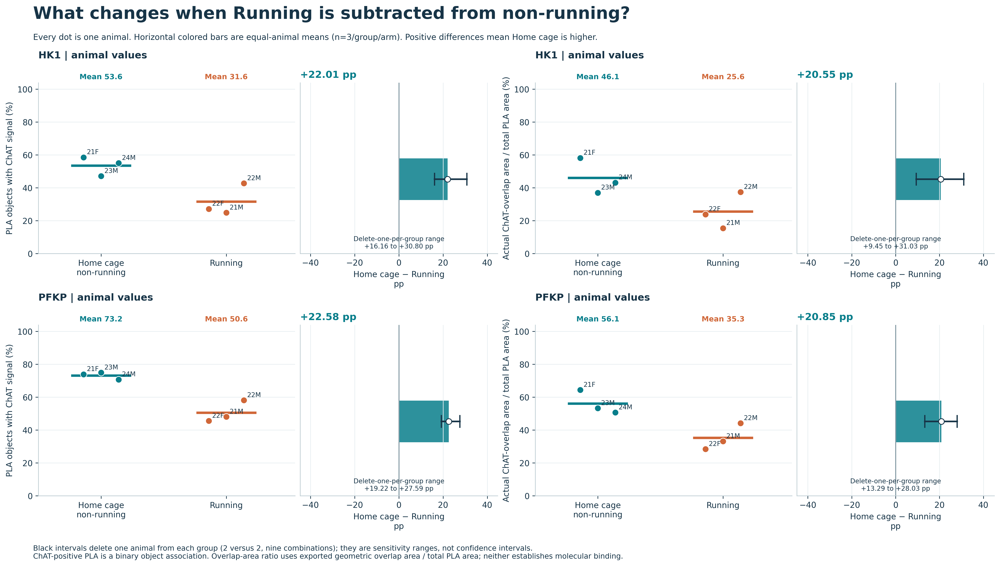

In [7]:
show(cv.average_difference_figure(condition_results), '13_condition_averages_difference')

### Normalization audit · what has actually been divided by what?

**Yes, the main association percentages are normalized to PLA count. They are not tissue-area densities or ChAT-opportunity-corrected effects.** The word “raw” in the size plot means *before size reweighting*, not unnormalized counts.

| Quantity | Calculation within each animal | What it corrects | What remains unresolved |
|---|---|---|---|
| Primary association | 100 × ChAT-positive PLA count / all PLA count | Different total PLA export counts | ChAT abundance/coverage, segmentation, tissue composition and section level |
| Group mean | Mean of three animal percentages, each weighted 1/3 | Prevents animals with more objects dominating | Three animals still provide limited biological replication |
| Common-size association | Sum of within-size percentages × shared size weights | Different proportions of small/large PLA | Within-bin size variation and other biological/technical differences |
| Actual overlap-area ratio | 100 × summed exported overlap area / summed PLA area | Expresses overlap relative to measured PLA area | Different estimand; repeated object area is not unique tissue area |
| PLA / ChAT counts | Number of exported detections | **No normalization** | Sampled area, detection sensitivity and section completeness |
| Difference / between-animal SE | Difference divided by √(s²Home/3 + s²Running/3) | Expresses gap relative to animal-to-animal variation | Not biological correction, a spatial Z-map, or a significance claim |

**Do not normalize each image to its own maximum before subtraction:** that would remove real magnitude differences. Map colors use shared scales; color scaling is a display choice. True tissue density needs a valid ROI area and x/y calibration. ChAT object counts cannot substitute for the fraction of tissue occupied by ChAT because segmentation fragments and object sizes differ. Microscopy research cautions that overlap and randomization depend on spatial structure; simply dividing by ChAT counts or scrambling independent pixels would not establish enrichment. [McDonald & Dunn, 2013](https://pmc.ncbi.nlm.nih.gov/articles/PMC4428547/).

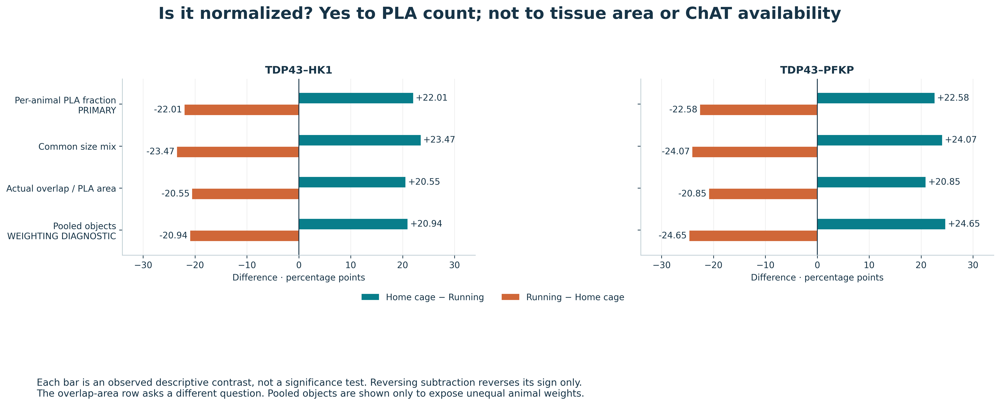

,pla_arm,direction,first_mean,reference_mean,difference_pp,relative_change_pct,ratio,between_animal_se_pp,difference_over_se,leave_pair_out_min,leave_pair_out_max
0,TDP43–HK1,Home cage − Running,53.586,31.580,22.006,69.684,1.697,6.548,3.361,16.156,30.798
1,TDP43–HK1,Running − Home cage,31.580,53.586,-22.006,-41.067,0.589,6.548,-3.361,-30.798,-16.156
2,TDP43–PFKP,Home cage − Running,73.203,50.618,22.585,44.618,1.446,4.043,5.586,19.219,27.593
3,TDP43–PFKP,Running − Home cage,50.618,73.203,-22.585,-30.852,0.691,4.043,-5.586,-27.593,-19.219


,pla_arm,animal_id,running_group,n_positive,pla_count,total_overlap_area_um2,total_pla_area_um2,association_pct,overlap_area_ratio_pct,equal_animal_weight_pct,pooled_object_weight_pct
0,TDP43–HK1,22F,Running,"3,437.000",12644,"2,012.327","8,438.703",27.183,23.846,33.333,26.284
1,TDP43–HK1,21F,Home cage,"19,574.000",33438,"13,488.469","23,175.774",58.538,58.201,33.333,22.740
2,TDP43–PFKP,22M,Running,"4,893.000",8412,"1,919.583","4,344.564",58.167,44.184,33.333,22.043
3,TDP43–PFKP,24M,Home cage,"5,470.000",7733,"2,344.615","4,627.052",70.736,50.672,33.333,10.080
4,TDP43–HK1,22M,Running,"6,402.000",14984,"3,840.487","10,266.367",42.726,37.408,33.333,31.148
5,TDP43–HK1,24M,Home cage,"22,710.000",41237,"9,348.140","21,662.494",55.072,43.154,33.333,28.044
6,TDP43–PFKP,21M,Running,"8,729.000",18160,"4,384.953","13,228.260",48.067,33.148,33.333,47.588
7,TDP43–PFKP,23M,Home cage,"33,814.000",45123,"10,528.512","19,772.656",74.937,53.248,33.333,58.821
8,TDP43–HK1,21M,Running,"5,085.000",20478,"2,495.491","16,157.550",24.832,15.445,33.333,42.568
9,TDP43–HK1,23M,Home cage,"34,121.000",72369,"17,250.904","46,631.242",47.149,36.994,33.333,49.216


In [8]:
show(norm.normalization_figure(condition_results), '17_normalization_both_directions')
display(condition_results['directions'])
display(condition_results['denominators'])

**Read subtraction from both sides.** The table and figure above show Home − Running and Running − Home. Their absolute differences are exact sign reversals, and the reversed sensitivity interval is [−upper, −lower]. These are the same observation with opposite signs, not corroborating tests. Relative percentage change uses the second group as denominator, so its magnitudes need not match after reversal. Both directions, ratios, animal-based SE and original denominators are exported and available in the app.

The pooled-object row deliberately shows what happens if one ignores the animal as the unit of replication. It is a weighting diagnostic, not an alternative result selected for its size. The app exposes the per-animal weights so the consequence can be inspected directly.

### Additional question · is the condition gap selective for one PLA arm?

For each animal, subtract its HK1-arm association from its PFKP-arm association, then compare those animal-level arm gaps across conditions. This uses repeated animal identities; **the sections are physically different and are not subtracted spatially**. The two assays may differ in detection efficiency, so this contrast is descriptive and cannot establish relative protein abundance or activity.

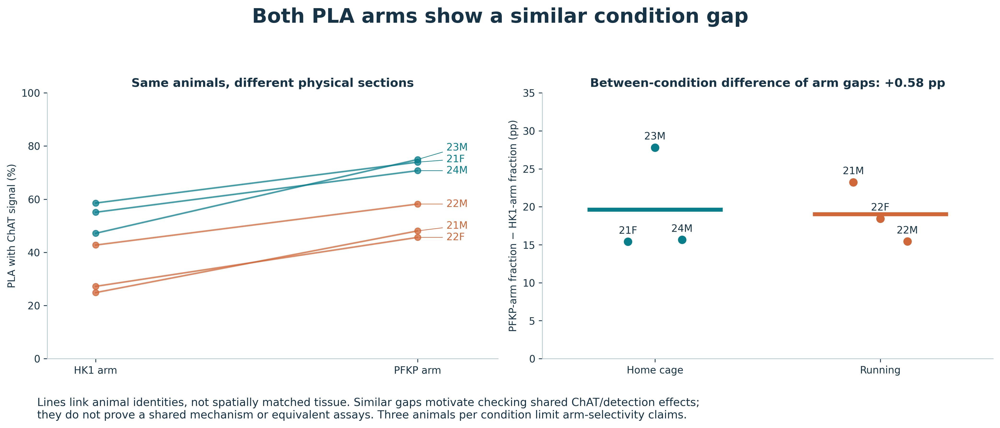

pla_arm,animal_id,running_group,TDP43–HK1,TDP43–PFKP,pfkp_minus_hk1_pp
0,21F,Home cage,58.538,73.936,15.398
1,21M,Running,24.832,48.067,23.236
2,22F,Running,27.183,45.621,18.438
3,22M,Running,42.726,58.167,15.441
4,23M,Home cage,47.149,74.937,27.789
5,24M,Home cage,55.072,70.736,15.664


**PFKP minus HK1:** Home cage 19.62 pp; Running 19.04 pp. The condition difference between those arm gaps is **+0.58 pp**. A strong claim of an arm-selective running response is not supported by these descriptive means. Prioritize shared ChAT staining/detection and tissue-composition checks before a mechanism-specific interpretation.

In [9]:
show(norm.paired_arm_figure(condition_results), '18_within_animal_arm_comparison')
arm_gaps = condition_results['paired_arms'].groupby('running_group').pfkp_minus_hk1_pp.mean()
display(condition_results['paired_arms'])
display(Markdown(f"**PFKP minus HK1:** Home cage {arm_gaps['Home cage']:.2f} pp; Running {arm_gaps['Running']:.2f} pp. "
                 f"The condition difference between those arm gaps is **{arm_gaps['Home cage']-arm_gaps['Running']:+.2f} pp**. "
                 "A strong claim of an arm-selective running response is not supported by these descriptive means. "
                 "Prioritize shared ChAT staining/detection and tissue-composition checks before a mechanism-specific interpretation."))

### Check 1 · Is the contrast driven by a single mouse?

The left heatmaps subtract each Running animal from each Home-cage animal. Their nine cells share animals; they are **not nine independent experiments**. The right heatmaps remove one animal per group and recompute the remaining two-versus-two mean difference. In this dataset, every cell is positive in both arms. This makes a single unusual animal an insufficient explanation for the observed direction, but does not remove a technical difference shared by a condition.

The second metric in the average figure is **summed exported overlap area / summed PLA area, calculated within each animal**. It differs from the percentage of objects flagged positive and from the area of all positive objects. It is not tissue coverage; overlapping segmented objects may contribute repeated area. The association gap is also positive with this alternate geometric summary.

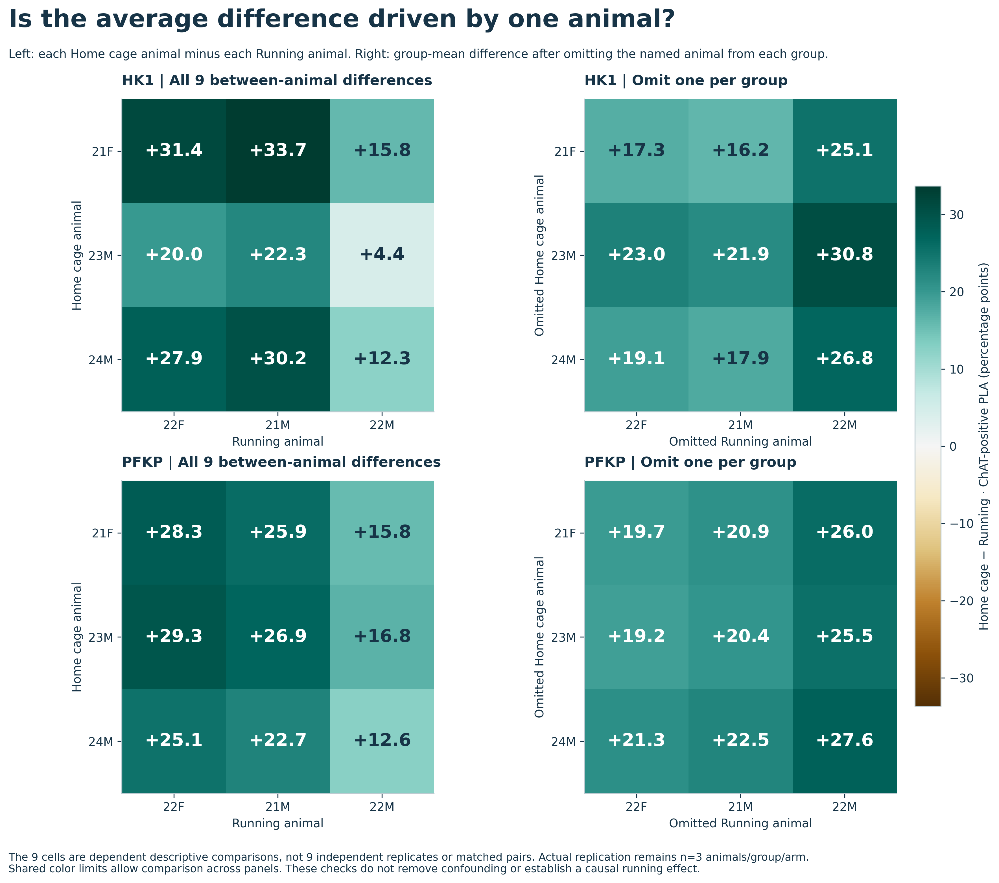

In [10]:
show(cv.robustness_figure(condition_results), '14_condition_robustness')

### Check 2 · Could the different PLA size mixture explain the averages?

Larger objects have more geometric opportunity to overlap ChAT. We therefore compare the same five predefined area classes, then give every animal a **common reference size distribution**. Within each arm, reference weights are the equal-animal average of the six animals' size-class proportions. Only classes with at least 10 PLA and an observed fraction in **every** animal are eligible; missing support is never a zero.

The plot separates **raw**, **restricted to supported sizes**, and **standardized to common size weights** estimates. Here all five classes meet support and all objects are retained, so raw and restricted coincide. Standardization changes the size mixture, not the original detections. Its delete-one-per-group sensitivity holds the full-cohort size weights and eligible classes fixed. It is an exploratory sensitivity analysis, not a causal adjustment or a substitute for reviewing detection settings, ChAT abundance and tissue support.

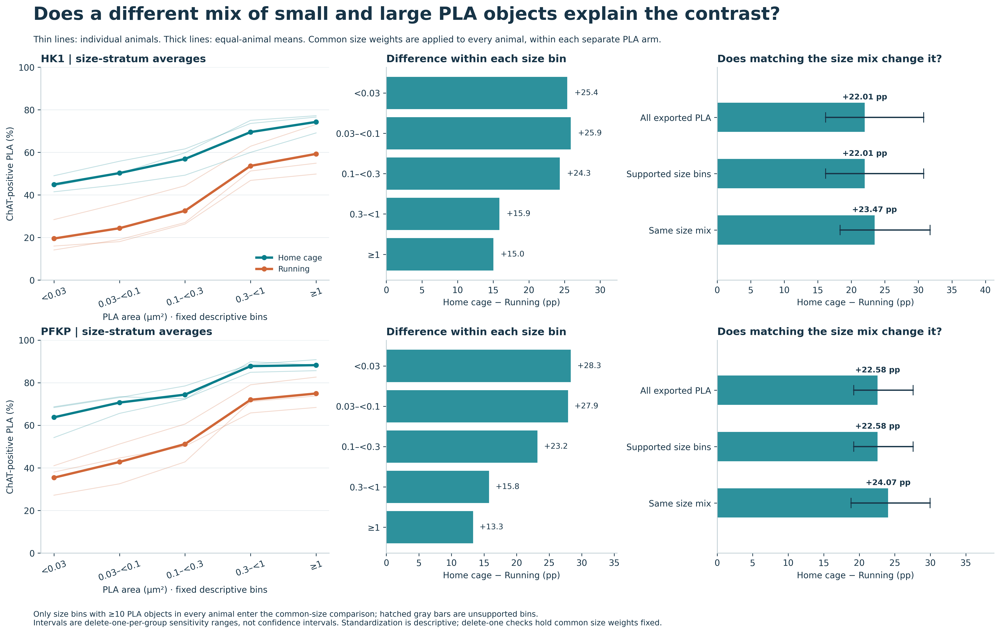

**TDP43–HK1:** after common-size reweighting, non-running **54.13%**, Running **30.67%**, difference **+23.47 percentage points**. Minimum animal retention: **100.0%**.

**TDP43–PFKP:** after common-size reweighting, non-running **73.48%**, Running **49.41%**, difference **+24.07 percentage points**. Minimum animal retention: **100.0%**.

In [11]:
show(cv.size_standardization_figure(condition_results), '15_condition_size_standardization')
for r in condition_results['standardization'].query("estimator == 'standardized'").itertuples():
    display(Markdown(f'**{r.pla_arm}:** after common-size reweighting, non-running **{r.home_mean:.2f}%**, '
                     f'Running **{r.running_mean:.2f}%**, difference **{r.home_minus_running:+.2f} percentage points**. '
                     f'Minimum animal retention: **{r.min_retained_pct:.1f}%**.'))

**What this adds:** size composition alone does not erase the association gap; the standardized gap is slightly larger. The size-specific means show the same direction across all five categories. That narrows one explanation, while leaving ChAT detection opportunity, tissue composition, acquisition and segmentation as unresolved alternatives. Avoid selecting a size cutoff solely because it strengthens the difference. [Dunn et al., 2011](https://pmc.ncbi.nlm.nih.gov/articles/PMC3074624/).

### Check 3 · Does source-image layout align with condition?

We can check the exported geometry without seeing the source microscopy pixels. The next figure compares raw bounding-box extents and the association difference within each shared source-image reference. Source-image sharing does **not** establish experimental pairing or identical settings. This is a technical audit, not a paired treatment test. If the X offsets were applied only after detection to assemble an export, those offsets alone cannot change the association fractions. The scientist should establish whether the layout reflects acquisition/processing differences or simply post-analysis placement.

,job,animal_id,running_group,pla_arm,image_id,image_label,x_min,x_max,y_min,...,n_objects,n_pla,n_positive,association_pct,x_mid,y_mid,x_width,y_height,extent_definition
0,4998,21F,Home cage,TDP43–HK1,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1,Image 1,"24,198.000","42,581.000","27,527.000",...,323082,33438,19574,58.538,"33,389.500","36,085.000","18,383.000","17,116.000",Envelope of exported object bounding boxes; no...
1,4997,22F,Running,TDP43–HK1,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1,Image 1,0.000,"20,214.000","25,314.000",...,163549,12644,3437,27.183,"10,107.000","34,683.500","20,214.000","18,739.000",Envelope of exported object bounding boxes; no...
2,5002,24M,Home cage,TDP43–HK1,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2,Image 2,"26,362.000","44,643.000","26,163.000",...,349776,41237,22710,55.072,"35,502.500","34,537.000","18,281.000","16,748.000",Envelope of exported object bounding boxes; no...
3,5001,22M,Running,TDP43–HK1,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2,Image 2,"1,681.000","21,301.000","23,641.000",...,237144,14984,6402,42.726,"11,491.000","32,324.500","19,620.000","17,367.000",Envelope of exported object bounding boxes; no...
4,5007,23M,Home cage,TDP43–HK1,20260515_173746_3_G9eDHt_Ellie_PLA_05152026_3,Image 3,"23,763.000","43,216.000","27,732.000",...,306291,72369,34121,47.149,"33,489.500","36,169.000","19,453.000","16,874.000",Envelope of exported object bounding boxes; no...
5,5006,21M,Running,TDP43–HK1,20260515_173746_3_G9eDHt_Ellie_PLA_05152026_3,Image 3,0.000,"17,922.000","26,556.000",...,176423,20478,5085,24.832,"8,961.000","35,599.500","17,922.000","18,087.000",Envelope of exported object bounding boxes; no...
6,5020,21F,Home cage,TDP43–PFKP,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1,Image 1,"23,680.000","43,273.000",0.000,...,240702,23857,17639,73.936,"33,476.500","7,305.000","19,593.000","14,610.000",Envelope of exported object bounding boxes; no...
7,5403,22F,Running,TDP43–PFKP,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1,Image 1,0.000,"21,106.000",532.000,...,190915,11589,5287,45.621,"10,553.000","8,883.000","21,106.000","16,702.000",Envelope of exported object bounding boxes; no...
8,5000,24M,Home cage,TDP43–PFKP,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2,Image 2,"25,902.000","44,643.000",0.000,...,295677,7733,5470,70.736,"35,272.500","6,845.000","18,741.000","13,690.000",Envelope of exported object bounding boxes; no...
9,4999,22M,Running,TDP43–PFKP,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2,Image 2,"2,398.000","22,152.000",0.000,...,184684,8412,4893,58.167,"12,275.000","6,546.500","19,754.000","13,093.000",Envelope of exported object bounding boxes; no...


,pla_arm,image_id,image_label,home_animals,running_animals,n_home,n_running,home_mean,running_mean,home_minus_running,x_order,x_gap_export_units,status
0,TDP43–HK1,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1,Image 1,21F,22F,1,1,58.538,27.183,31.355,Running lower-X; Home cage higher-X,"3,984.000",Descriptive within-source-image contrast; not ...
1,TDP43–HK1,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2,Image 2,24M,22M,1,1,55.072,42.726,12.346,Running lower-X; Home cage higher-X,"5,061.000",Descriptive within-source-image contrast; not ...
2,TDP43–HK1,20260515_173746_3_G9eDHt_Ellie_PLA_05152026_3,Image 3,23M,21M,1,1,47.149,24.832,22.317,Running lower-X; Home cage higher-X,"5,841.000",Descriptive within-source-image contrast; not ...
3,TDP43–PFKP,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1,Image 1,21F,22F,1,1,73.936,45.621,28.316,Running lower-X; Home cage higher-X,"2,574.000",Descriptive within-source-image contrast; not ...
4,TDP43–PFKP,20260515_173745_2_jqw0p1_Ellie_PLA_05152026_2,Image 2,24M,22M,1,1,70.736,58.167,12.569,Running lower-X; Home cage higher-X,"3,750.000",Descriptive within-source-image contrast; not ...
5,TDP43–PFKP,20260515_173746_3_G9eDHt_Ellie_PLA_05152026_3,Image 3,23M,21M,1,1,74.937,48.067,26.870,Running lower-X; Home cage higher-X,"5,327.000",Descriptive within-source-image contrast; not ...


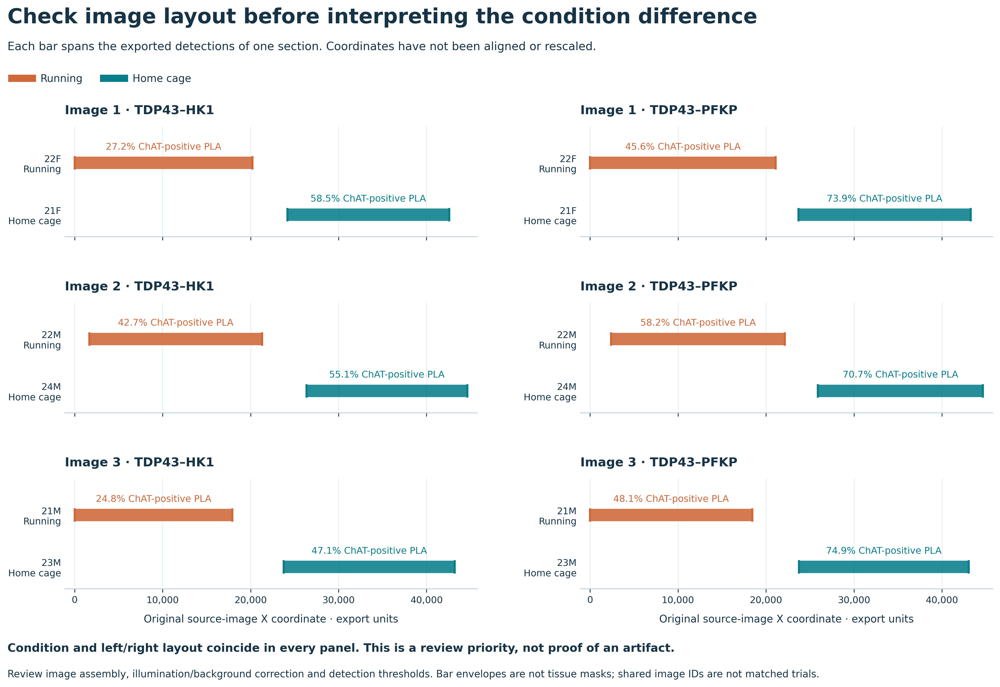

**Source-image review priority:** in the current exports, Running sections occupy the lower-X side and Home-cage sections the higher-X side across all three image references and both arms. This does **not** prove an artifact. Request the original channels and image/composite construction history, then compare illumination/background, ChAT segmentation and HALO thresholds across equivalent fields blinded to condition. The shared image references cannot separate a condition effect from a condition-aligned layout effect.

In [12]:
layout_sections, layout_image_contrasts, layout_summary = cl.layout_audit(objects, metadata)
table(layout_sections, 'condition_image_layout_sections')
table(layout_image_contrasts, 'condition_source_image_contrasts')
(TABLES / 'condition_image_layout_summary.json').write_text(json.dumps(layout_summary, indent=2, ensure_ascii=False) + '\n')
show(cl.layout_figure(layout_sections), '16_condition_image_layout')
display(Markdown('**Source-image review priority:** in the current exports, Running sections occupy the lower-X side and Home-cage sections the higher-X side across all three image references and both arms. This does **not** prove an artifact. Request the original channels and image/composite construction history, then compare illumination/background, ChAT segmentation and HALO thresholds across equivalent fields blinded to condition. The shared image references cannot separate a condition effect from a condition-aligned layout effect.'))

### What would an anatomical difference map require?

Overlaying centered silhouettes is useful for geometry review, but subtracting their biological signal would assume that the locations correspond. **No section is currently approved for this anatomical comparison.** The review gate later in this notebook computes per-animal fractions, equal-animal Home/Running means, **Home − Running**, and both contributing-animal maps only after all 12 records pass. Each displayed group bin requires three supported animals; absent support stays blank. The separate spatial explorer can already show native measurements and provisional geometry layers.

### How much evidence do six animals provide?

The observed direction is consistent, but population uncertainty remains substantial. An optional exact enumeration places three of six animals in each group in all **20 possible allocations**; both primary contrasts have two-sided value **0.10**, the minimum attainable here. This calculation assumes exchangeable animal labels, which the handoff does not establish. It is saved as a **design-limit diagnostic**, not a confirmatory significance claim or evidence of no difference. No pixel or punctum is treated as an independent animal. [SciPy exact-permutation documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).

In [13]:
display(condition_results['exact_summary'])

,pla_arm,observed_difference,two_sided_p,allocations,min_attainable_p,status
0,TDP43–HK1,22.006,0.100,20,0.100,Exploratory label-enumeration diagnostic; exch...
1,TDP43–PFKP,22.585,0.100,20,0.100,Exploratory label-enumeration diagnostic; exch...


### Align the visible image features · a concrete improvement to the layers

The old overlay retained native image offsets by default. Its automatic enclosed-hole detector also missed **3/12 cavities** and often traced only part of a cavity. The new default **Feature-aligned** view uses **12 inspectable cavity trace proposals**, drawn from the 100-unit all-detection reconstructions. These are computational visual annotations, not source-microscopy annotations or investigator approvals. Five traces have visibly ambiguous boundaries and are explicitly flagged.

1. Calculate the geometric centroid of each proposed internal-cavity polygon. Translation is fixed by that anchor, even when external tissue is cut off.
2. Within each PLA arm, use 21F as a fixed orientation reference. Where identifiable, annotate the adjacent loop-like structure and match its **above/below relationship to the cavity** to the reference. This selects the vertical orientation family without changing the cavity anchor; horizontal handedness is still geometric. If the cue is not identifiable (21M/PFKP), retain all four possibilities and flag it. Rank the remaining **none / horizontal / vertical / both flips** using the mean nearest-boundary distance in both directions after dropping the largest 20% of distances in each direction. Boundaries come from all-object occupancy, with one-bin closing and the largest connected component; PLA positivity and condition contrast do not select the transform.
3. Record every flip score, the full 90th-percentile residual and the margin between the best two flips. A margin below 10% is an ambiguity flag, not a statistical confidence threshold. Retain the unrestricted boundary-only winner too: **22F/PFKP changes from none to vertical when the internal cue is used**, showing why the exterior alone is insufficient. The cue is visually proposed homology, not independently validated anatomy. Repeat flip ranking at 500-unit bins and flag any disagreement with the primary 250-unit geometry. The untrimmed residual exposes mismatches that the robust score downweights. No continuous rotation, rescaling, warping or missing-tissue reconstruction is performed.

Partial-image registration research supports using surviving characteristic shape features when the exterior is incomplete. Our simpler, handoff-constrained method is a **proposal**, not a replication or validation of that method. A low fitting residual is not independent target-registration accuracy. The cavity is the anchor; independent source-image landmarks, expected cut edge and section-level metadata must validate it. [Pichat et al., 2017](https://arxiv.org/abs/1708.08117), [local handoff, pp. 4–9](HALO_spatial_analysis_raw_data_handoff.pdf).

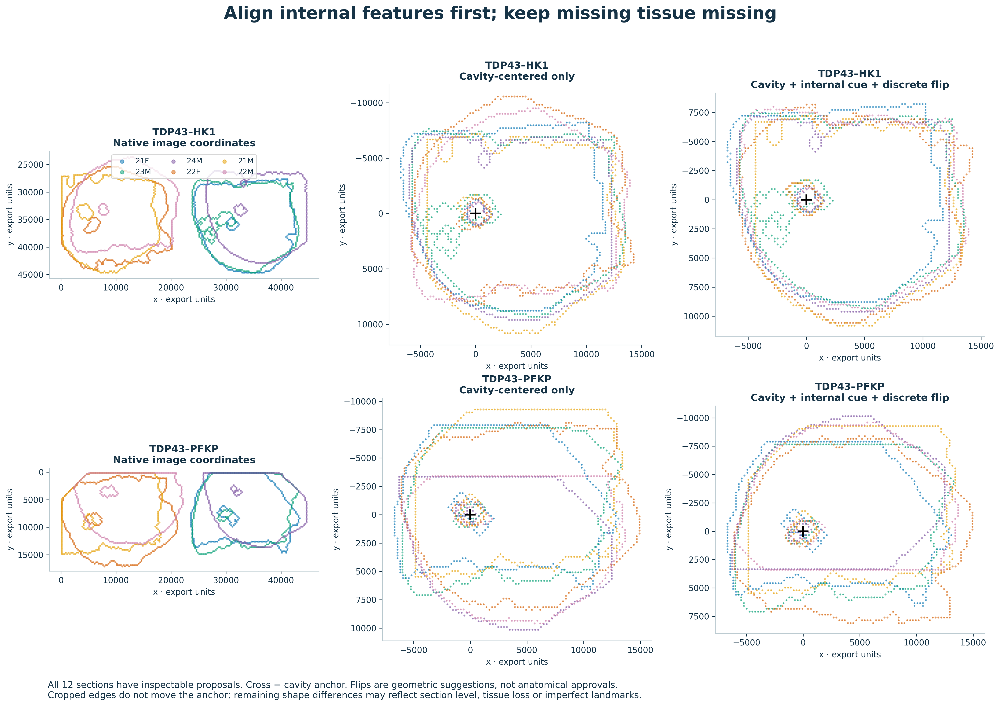

,animal_id,pla_arm,job,flip,ambiguous_boundary,flip_ambiguous,native_boundary_distance,centered_boundary_distance,aligned_boundary_distance,boundary_p90,flip_margin_fraction,boundary_best_flip,cue_boundary_conflict,orientation_cue_used,coarse_flip,flip_resolution_stable
0,21F,TDP43–HK1,4998,none,False,False,0.000,0.000,0.000,0.000,1.000,none,False,True,none,True
1,23M,TDP43–HK1,5007,none,True,False,350.563,600.549,600.549,"1,872.722",0.727,none,False,True,none,True
2,24M,TDP43–HK1,5002,none,False,False,"1,548.158",526.405,526.405,"1,340.465",0.773,none,False,True,none,True
3,22F,TDP43–HK1,4997,vertical,True,False,"12,789.020",816.116,729.929,"2,286.456",0.702,vertical,False,True,vertical,True
4,21M,TDP43–HK1,5006,none,False,False,"14,960.055",917.577,917.577,"2,162.214",0.607,none,False,True,none,True
5,22M,TDP43–HK1,5001,vertical,False,False,"11,450.351",903.945,513.665,"1,861.606",0.785,vertical,False,True,vertical,True
6,21F,TDP43–PFKP,5020,none,True,False,0.000,0.000,0.000,0.000,1.000,none,False,True,none,True
7,23M,TDP43–PFKP,5005,none,False,False,382.907,529.764,529.764,"1,985.115",0.676,none,False,True,none,True
8,24M,TDP43–PFKP,5000,vertical,False,False,930.462,"1,470.380",972.853,"2,402.758",0.465,vertical,False,True,vertical,True
9,22F,TDP43–PFKP,5403,vertical,True,False,"10,856.801",901.424,944.051,"2,588.237",0.588,none,True,True,vertical,True


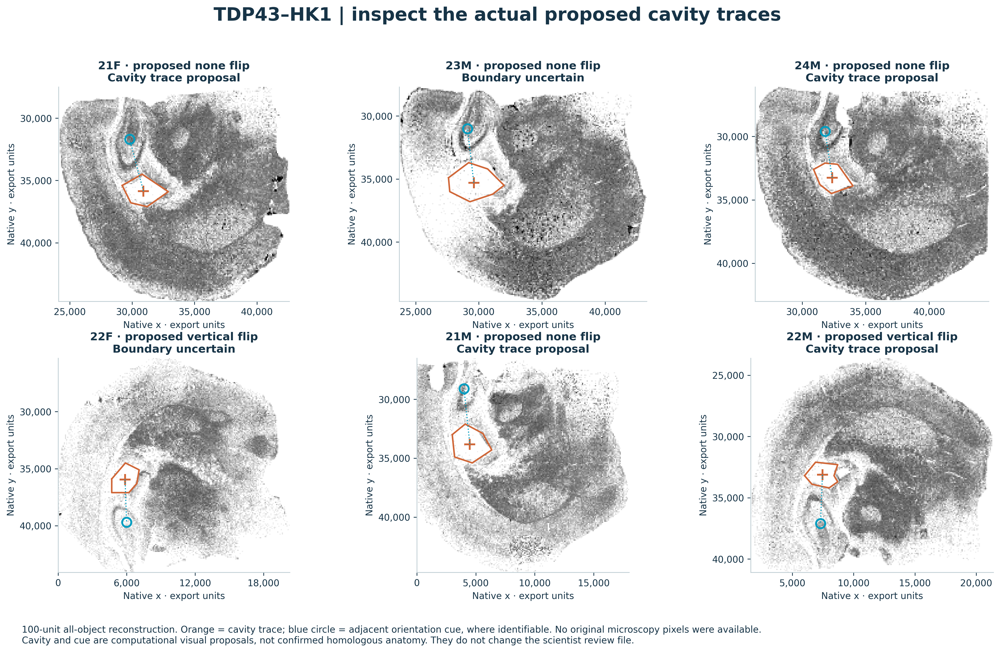

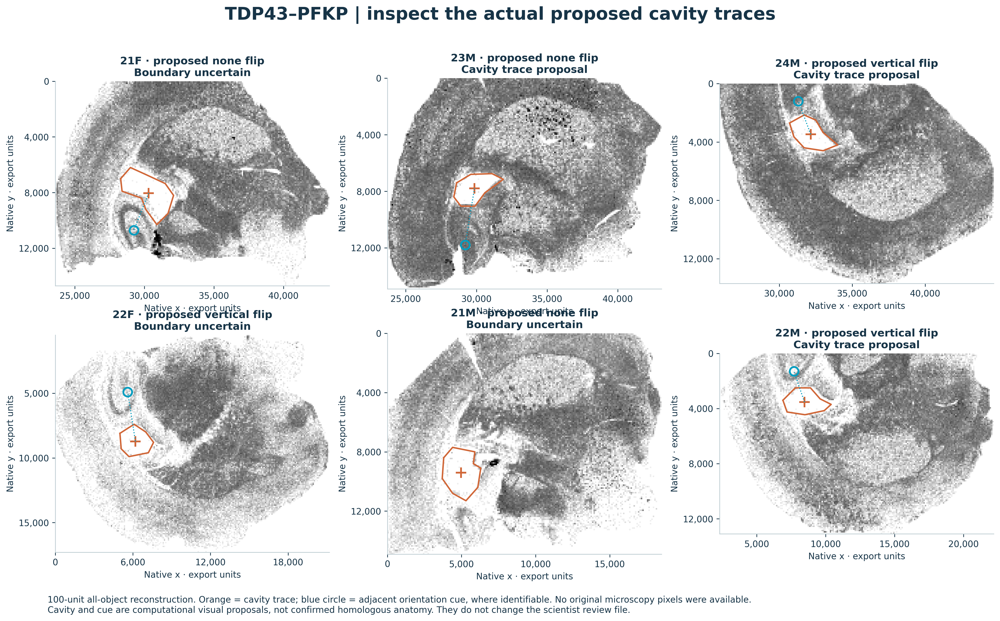

In [14]:
show(fa.alignment_figure(geometry, alignment_proposals), '19_feature_alignment_before_after')
alignment_table = pd.DataFrame(alignment_proposals)
table(alignment_table[['animal_id','pla_arm','job','flip','ambiguous_boundary','flip_ambiguous',
                       'native_boundary_distance','centered_boundary_distance','aligned_boundary_distance',
                       'boundary_p90','flip_margin_fraction','boundary_best_flip','cue_boundary_conflict',
                       'orientation_cue_used','coarse_flip','flip_resolution_stable']], 'alignment_geometry_diagnostics')
for arm, key in [('TDP43–HK1','hk1'),('TDP43–PFKP','pfkp')]:
    show(fa.landmark_figure(fine, alignment_proposals, arm), f'20_proposed_cavity_traces_{key}')

**Inspect it interactively:** choose **Overlapping layers → Feature-aligned**, then flat overlay or 3D stack. Cavity outlines, a shared anchor and the adjacent-structure cue remain visible; toggle animals or step one at a time. Switch to **Native image coordinates** for the before view, or **Candidate-centered** for the old automated proposals. Feature-aligned mode may display each section’s measured values, but it never pools animals or turns a tentative overlap into an anatomical group difference. Every object retains its measured value and spacing.

**What still needs the scientist:** confirm the traced cavity in each original image, independently review proposed flips and the expected cut edge, verify common coordinate scale and section level, and supply tissue ROI masks. No approval records were changed. All 12 sections are visible for review now; group anatomical subtraction remains gated until correspondence and support are defensible. Missing tissue stays unmeasured rather than being filled from another animal.

<a id="machine-learning"></a>
## Exploratory machine learning · what size and shape reveal

**Question:** does the Home-cage–Running ChAT-association difference mainly reflect a different mixture of PLA object shapes, or does it persist among similarly measured objects? The model learns a small dictionary of PLA **measurement patterns**. It then locates those patterns and compares association within them. This extends the fixed size-bin checks; it does not change the primary measurements.

**[Open the machine-learning explorer](http://127.0.0.1:8050/#machine-learning)** after launching the app. All numerical results, static figures and interactive controls also appear below.

### Scientific process and safeguards

1. **Choose fitting inputs without condition labels or ChAT outcomes.** Use log₁₀ exported PLA area and minimum/maximum diameter. A ratio near 1 means similar reported diameters; a lower ratio means a greater difference between them. A zero minimum is a measurement limit to review, not evidence of elongation. This is an exported shape descriptor, not a segmentation contour or cell identity. Zero minimum diameter remains a recorded value when the maximum is positive; invalid area, invalid diameter order or zero maximum cannot supply both features. Report these exclusions separately. No imputation and no change to the full-data primary analysis.
2. **Learn without the answer.** Sample equally from every animal within each arm, fit median/IQR scaling, and fit K-means with three groups. Running status, ChAT flags/overlap, image coordinates and intensity are excluded from fitting. Intensity is omitted because its channel/acquisition comparability is not established. Each arm has its own dictionary: a group number does not identify the same biological population across arms.
3. **Check model dependence.** Repeat with two and four groups without selecting the number that maximizes the condition difference. Leave out each animal, refit both scaling and clustering on the other five, and compare assignments on the omitted animal with the full-data reference. These are stability checks; the reference itself used all animals, so agreement is **not out-of-sample predictive accuracy**.
4. **Reveal the outcomes after fitting.** Calculate morphology-group abundance and ChAT association within each animal. Average animals equally. Apply the same group mixture to every animal as a descriptive sensitivity check, requiring at least 10 eligible PLA objects in every animal for an included group. Compare this to the unadjusted eligible-object result and the all-PLA result so excluded measurements cannot silently change the denominator.
5. **Return to the microscope.** Map the groups in native coordinates and export representative and extreme detections with source job, object ID and review windows. Extreme means unusual under this measurement model—not an error, disease state or automatically removable observation.

K-means partitions continuous measurements even when nature has no discrete classes. We therefore call these *morphology groups*, not discovered cell types. Morphology profiling can prioritize biological hypotheses, but mechanistic interpretations need independent experiments ([Rohban et al., 2017](https://elifesciences.org/articles/24060)). Animal-grouped refits address repeated-subject leakage ([Rosenblatt et al., 2024](https://www.nature.com/articles/s41467-024-46150-w)); six animals are insufficient for a credible running-status predictor ([Varoquaux, 2018](https://pubmed.ncbi.nlm.nih.gov/28655633/)). Cluster stability does not establish biological meaning ([Hennig, 2007](https://www.homepages.ucl.ac.uk/~ucakche/papers/clusta.pdf)).

,job,animal_id,running_group,pla_arm,n_pla,n_valid,n_excluded,retained_pct,nonfinite_morphology_n,nonpositive_area_n,nonpositive_max_diameter_n,min_greater_than_max_n,negative_min_n,retained_zero_min_n,both_zero_diameters_n,missing_association_n,missing_valid_coordinates_n
0,4997,22F,Running,TDP43–HK1,12644,10931,1713,86.452,0,0,1713,0,0,1547,1713,0,0
1,4998,21F,Home cage,TDP43–HK1,33438,28421,5017,84.996,0,0,5017,0,0,4860,5017,0,0
2,4999,22M,Running,TDP43–PFKP,8412,7312,1100,86.923,0,0,1100,0,0,938,1100,0,0
3,5000,24M,Home cage,TDP43–PFKP,7733,6800,933,87.935,0,0,933,0,0,880,933,0,0
4,5001,22M,Running,TDP43–HK1,14984,13030,1954,86.959,0,0,1954,0,0,1827,1954,0,0
5,5002,24M,Home cage,TDP43–HK1,41237,34561,6676,83.811,0,0,6676,0,0,6230,6676,0,0
6,5003,21M,Running,TDP43–PFKP,18160,15389,2771,84.741,0,0,2771,0,0,2565,2771,0,0
7,5005,23M,Home cage,TDP43–PFKP,45123,36703,8420,81.340,0,0,8420,0,0,7349,8420,0,0
8,5006,21M,Running,TDP43–HK1,20478,17287,3191,84.417,0,0,3191,0,0,3045,3191,0,0
9,5007,23M,Home cage,TDP43–HK1,72369,59122,13247,81.695,0,0,13247,0,0,12163,13247,0,0


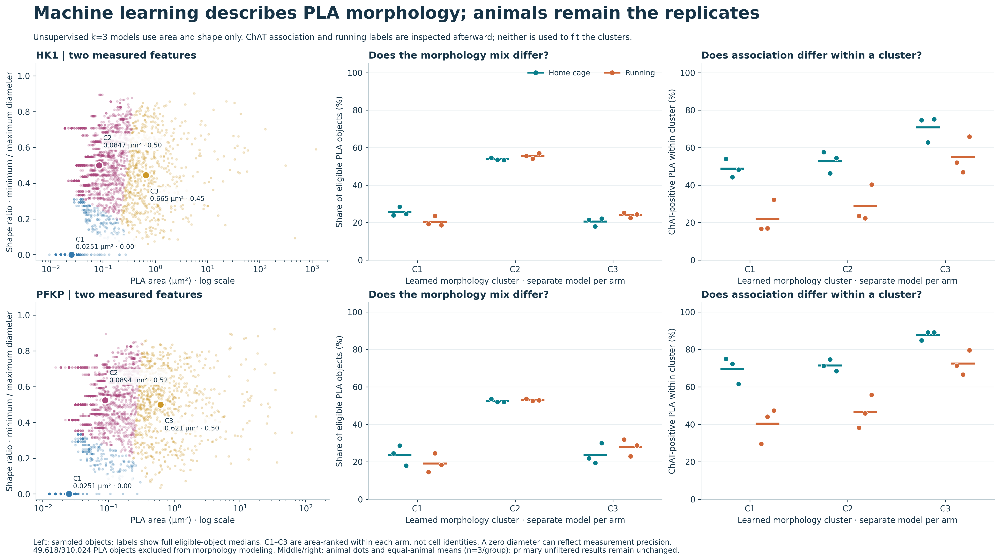

In [15]:
ml_results = ml.run_analysis(objects, metadata)
for name, value in ml_results.items():
    if isinstance(value, pd.DataFrame):
        value.to_csv(TABLES / ('ml_' + name + '.csv.gz'), index=False, compression='gzip')
(TABLES / 'ml_definitions.json').write_text(json.dumps(ml_results['definitions'], indent=2, ensure_ascii=False, allow_nan=False) + '\n')
display(ml_results['audit'])
show(mv.overview_figure(ml_results), '21_morphology_patterns')

In [16]:
ml_audit = ml_results['audit']
n_valid, n_pla = int(ml_audit.n_valid.sum()), int(ml_audit.n_pla.sum())
ml_findings = [f'### Findings from this run\n\nThe size-and-shape model includes **{n_valid:,}/{n_pla:,} PLA detections ({100*n_valid/n_pla:.1f}%)**. '
               f'The remaining **{n_pla-n_valid:,}** stay in the primary analysis and the area-only sensitivity where area is valid.']
for arm in sorted(ml_results['standardized'].pla_arm.unique()):
    s = ml_results['standardized'].query('pla_arm == @arm and k == 3').iloc[0]
    a = ml_results['area_only_standardized'].query('pla_arm == @arm').iloc[0]
    contrasts = ml_results['contrasts'].query('pla_arm == @arm and metric == "association_pct"')
    stable = ml_results['stability'].query('pla_arm == @arm')
    jaccard = ml_results['stability_clusters'].query('pla_arm == @arm').jaccard
    text = (f'**{arm}:** Home cage minus Running is **{s.raw_difference_pp:.2f} percentage points** in all PLA, '
            f'**{s.valid_difference_pp:.2f} pp** among usable morphology measurements, and '
            f'**{s.standardized_difference_pp:.2f} pp** after applying the common three-group morphology mixture. '
            f'The area-only sensitivity gives **{a.standardized_difference_pp:.2f} pp**, retaining {a.input_coverage_pct:.1f}% of PLA. '
            f'Within-group differences range from **{contrasts.difference_pp.min():.2f} to {contrasts.difference_pp.max():.2f} pp**. '
            f'The morphology standardization retains {s.retained_pct:.1f}% of eligible measurements across supported groups. '
            f'Leaving an animal out yields adjusted Rand agreement **{stable.ari.min():.3f}–{stable.ari.max():.3f}**; '
            f'the lowest group-specific Jaccard agreement is **{jaccard.min():.3f}**. These measure partition stability, not biological validation.')
    ml_findings.append(text)
    weakest = stable.loc[stable.ari.idxmin()]
    ml_findings.append(f'**Stability review priority: {weakest.animal_id} in {arm}.** Leaving this animal out produces the lowest adjusted Rand agreement '
                       f'({weakest.ari:.3f}); {weakest.agreement_pct:.1f}% of its assigned labels match the full-data reference. '
                       'Inspect this section’s measurement distribution and representative crops before treating cluster boundaries as reproducible biological groups.')
    profiles = ml_results['profiles'].query('pla_arm == @arm').sort_values('cluster')
    small, large = profiles.iloc[0], profiles.iloc[-1]
    mix = ml_results['contrasts'].query('pla_arm == @arm and metric == "proportion_pct"')
    large_mix = mix.loc[mix.cluster.eq(large.cluster)].iloc[0]
    small_gap = contrasts.loc[contrasts.cluster.eq(small.cluster), 'difference_pp'].iloc[0]
    large_gap = contrasts.loc[contrasts.cluster.eq(large.cluster), 'difference_pp'].iloc[0]
    ml_findings.append(f'**A concrete review lead for {arm}:** the smallest-area group has median area **{small.median_area:.4f} µm²**, '
                       f'and **{small.zero_min_pct:.1f}%** of its detections have zero exported minimum diameter. '
                       f'Its association gap is **{small_gap:.2f} pp**, versus **{large_gap:.2f} pp** in the largest-area group. '
                       f'The largest-area group represents **{large_mix.home_pct:.1f}%** of eligible Home-cage PLA and '
                       f'**{large_mix.running_pct:.1f}%** of eligible Running PLA. '
                       'Inspect the small, diameter-limited detections first, while also checking representative large detections; '
                       'these descriptive patterns do not establish biological object classes.')
ml_findings.append('**Interpretation:** inspect the direction and magnitude across the full-data, eligible-data, common-mixture and area-only results together. '
                   'A persistent gap across these checks is not explained solely by this coarse size/shape mixture. It remains compatible with biological differences, marker availability or detection/acquisition differences; this model does not separate those explanations. '
                   'A shape ratio of zero reflects an exported zero minimum diameter, so inspect those groups for measurement-resolution or segmentation effects before calling them elongated structures.')
display(Markdown('\n\n'.join(ml_findings)))
display(ml_results['profiles'])
display(ml_results['area_only_standardized'])

### Findings from this run

The size-and-shape model includes **260,406/310,024 PLA detections (84.0%)**. The remaining **49,618** stay in the primary analysis and the area-only sensitivity where area is valid.

**TDP43–HK1:** Home cage minus Running is **22.01 percentage points** in all PLA, **21.85 pp** among usable morphology measurements, and **22.89 pp** after applying the common three-group morphology mixture. The area-only sensitivity gives **23.26 pp**, retaining 100.0% of PLA. Within-group differences range from **15.89 to 26.87 pp**. The morphology standardization retains 100.0% of eligible measurements across supported groups. Leaving an animal out yields adjusted Rand agreement **0.965–0.981**; the lowest group-specific Jaccard agreement is **0.954**. These measure partition stability, not biological validation.

**Stability review priority: 21M in TDP43–HK1.** Leaving this animal out produces the lowest adjusted Rand agreement (0.965); 98.9% of its assigned labels match the full-data reference. Inspect this section’s measurement distribution and representative crops before treating cluster boundaries as reproducible biological groups.

**A concrete review lead for TDP43–HK1:** the smallest-area group has median area **0.0251 µm²**, and **72.9%** of its detections have zero exported minimum diameter. Its association gap is **26.87 pp**, versus **15.89 pp** in the largest-area group. The largest-area group represents **20.6%** of eligible Home-cage PLA and **24.0%** of eligible Running PLA. Inspect the small, diameter-limited detections first, while also checking representative large detections; these descriptive patterns do not establish biological object classes.

**TDP43–PFKP:** Home cage minus Running is **22.58 percentage points** in all PLA, **22.20 pp** among usable morphology measurements, and **23.30 pp** after applying the common three-group morphology mixture. The area-only sensitivity gives **23.93 pp**, retaining 100.0% of PLA. Within-group differences range from **15.19 to 29.27 pp**. The morphology standardization retains 100.0% of eligible measurements across supported groups. Leaving an animal out yields adjusted Rand agreement **0.754–0.996**; the lowest group-specific Jaccard agreement is **0.784**. These measure partition stability, not biological validation.

**Stability review priority: 21M in TDP43–PFKP.** Leaving this animal out produces the lowest adjusted Rand agreement (0.754); 91.6% of its assigned labels match the full-data reference. Inspect this section’s measurement distribution and representative crops before treating cluster boundaries as reproducible biological groups.

**A concrete review lead for TDP43–PFKP:** the smallest-area group has median area **0.0251 µm²**, and **69.4%** of its detections have zero exported minimum diameter. Its association gap is **29.27 pp**, versus **15.19 pp** in the largest-area group. The largest-area group represents **23.8%** of eligible Home-cage PLA and **27.8%** of eligible Running PLA. Inspect the small, diameter-limited detections first, while also checking representative large detections; these descriptive patterns do not establish biological object classes.

**Interpretation:** inspect the direction and magnitude across the full-data, eligible-data, common-mixture and area-only results together. A persistent gap across these checks is not explained solely by this coarse size/shape mixture. It remains compatible with biological differences, marker availability or detection/acquisition differences; this model does not separate those explanations. A shape ratio of zero reflects an exported zero minimum diameter, so inspect those groups for measurement-resolution or segmentation effects before calling them elongated structures.

,pla_arm,cluster,median_area,median_shape,n,zero_min_pct,center_log10_area,center_shape
0,TDP43–HK1,1,0.025,0.000,40671,72.897,-1.513,0.057
1,TDP43–HK1,2,0.085,0.500,88466,0.000,-1.041,0.527
2,TDP43–HK1,3,0.665,0.446,34215,0.070,-0.034,0.456
3,TDP43–PFKP,1,0.025,0.000,23369,69.400,-1.490,0.069
4,TDP43–PFKP,2,0.089,0.524,51064,0.000,-1.022,0.544
5,TDP43–PFKP,3,0.621,0.500,22621,0.022,-0.087,0.508


,pla_arm,k,raw_difference_pp,valid_difference_pp,eligible_difference_pp,standardized_difference_pp,home_standardized_pct,running_standardized_pct,retained_pct,min_retained_pct,min_cluster_n,eligible_clusters,feature,valid_pla_n,morphology_pla_n,input_coverage_pct,morphology_coverage_pct
0,TDP43–HK1,3,22.006,22.006,22.006,23.264,54.065,30.802,100.000,100.000,2559,3,log10(area) only; no diameter requirement,195150,163352,100.000,83.706
1,TDP43–PFKP,3,22.585,22.585,22.585,23.933,73.463,49.530,100.000,100.000,1955,3,log10(area) only; no diameter requirement,114874,97054,100.000,84.487


### Reading the learned patterns

Read the scatter as a map of measured size and shape, then compare **individual animal dots**. The scatter is a deterministic display sample; summaries use every eligible PLA object. Group abundance is the percentage of eligible PLA assigned to that morphology group. Association is the percentage with ChAT signal **within that group in that animal**. Different denominators answer different questions. Neither is normalized to tissue area or ChAT availability.

Compare the same morphology group across conditions within an arm. A persistent association difference among similar size/shape groups makes a simple composition-only explanation less sufficient; it does not remove image layout, thresholding, sampled anatomy or marker-availability confounding. No automatic clusterwise significance testing or condition classifier is used.

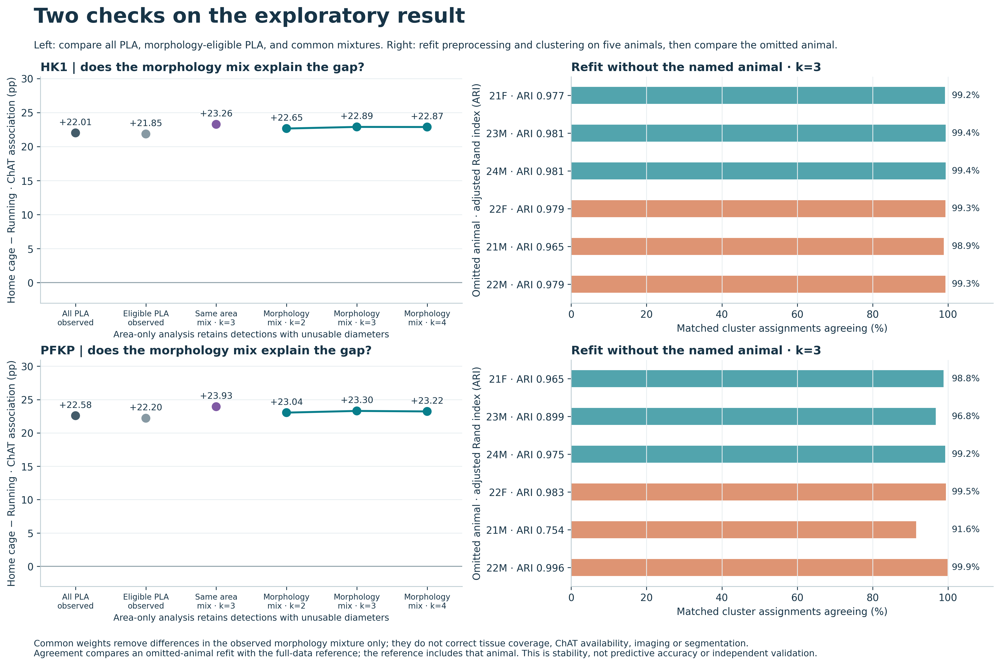

,pla_arm,k,raw_difference_pp,valid_difference_pp,eligible_difference_pp,standardized_difference_pp,home_standardized_pct,running_standardized_pct,retained_pct,min_retained_pct,min_cluster_n,eligible_clusters
0,TDP43–HK1,2,22.006,21.848,21.848,22.649,55.800,33.150,100.000,100.000,2864,2
1,TDP43–HK1,3,22.006,21.848,21.848,22.885,55.893,33.008,100.000,100.000,2097,3
2,TDP43–HK1,4,22.006,21.848,21.848,22.869,55.897,33.028,100.000,100.000,1569,4
3,TDP43–PFKP,2,22.585,22.202,22.202,23.043,75.132,52.089,100.000,100.000,1920,2
4,TDP43–PFKP,3,22.585,22.202,22.202,23.296,75.237,51.941,100.000,100.000,1222,3
5,TDP43–PFKP,4,22.585,22.202,22.202,23.221,75.216,51.996,100.000,100.000,895,4


,pla_arm,animal_id,ari,agreement_pct,fit_animals,heldout_n,n_per_training_animal
0,TDP43–HK1,21F,0.977,99.233,"21M,22F,22M,23M,24M",28421,3000
1,TDP43–HK1,21M,0.965,98.889,"21F,22F,22M,23M,24M",17287,3000
2,TDP43–HK1,22F,0.979,99.332,"21F,21M,22M,23M,24M",10931,3000
3,TDP43–HK1,22M,0.979,99.317,"21F,21M,22F,23M,24M",13030,3000
4,TDP43–HK1,23M,0.981,99.383,"21F,21M,22F,22M,24M",59122,3000
5,TDP43–HK1,24M,0.981,99.384,"21F,21M,22F,22M,23M",34561,3000
6,TDP43–PFKP,21F,0.965,98.839,"21M,22F,22M,23M,24M",20325,3000
7,TDP43–PFKP,21M,0.754,91.591,"21F,22F,22M,23M,24M",15389,3000
8,TDP43–PFKP,22F,0.983,99.468,"21F,21M,22M,23M,24M",10525,3000
9,TDP43–PFKP,22M,0.996,99.877,"21F,21M,22F,23M,24M",7312,3000


In [17]:
show(mv.robustness_figure(ml_results), '22_morphology_stability')
display(ml_results['standardized'])
display(ml_results['stability'])

### Locate the patterns and choose concrete follow-up fields

The controls below show **one physical section at a time** in native coordinates. A map value is the percentage of eligible PLA in that bin assigned to the selected morphology group. Bins with fewer than 10 eligible PLA are blank; blank is not zero. Inspect count support on hover. The additional **Excluded shape measurements** map uses all PLA as its denominator, revealing where unusable diameters occur; its percentages are not morphology-group abundance. There is no interpolation, anatomical pooling or recovered microscopy texture.

The spatial panels use the same 500-unit bin width for every section. Export x/y units remain uncalibrated. High-resolution figure export improves readability, not the physical resolution of the measurements. Source photographs and ROI masks are still needed to judge edges, merged detections and biological structures.

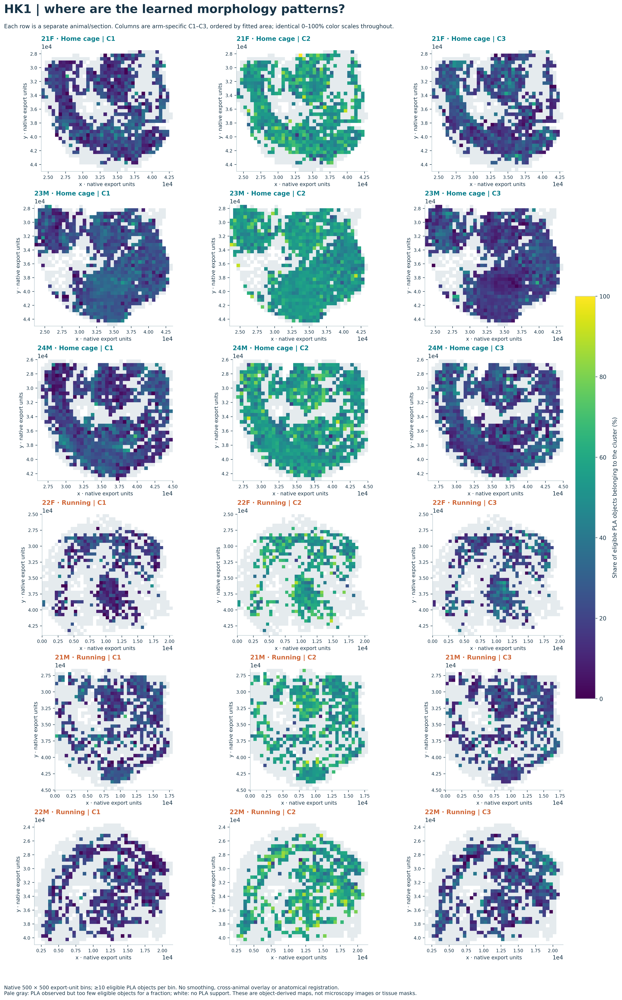

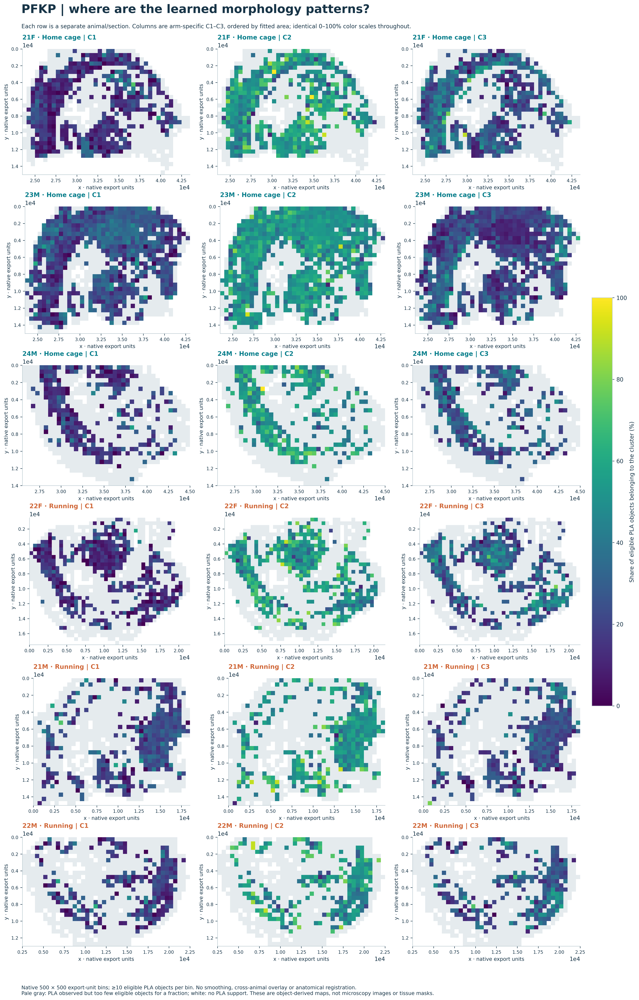

,job,animal_id,running_group,pla_arm,cluster,selection,object_id,source_file,x,y,area,shape,chat_present,window_xmin,window_xmax,window_ymin,window_ymax,reason
0,4997,22F,Running,TDP43–HK1,1,Typical measurement,987,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"6,068.000","26,991.000",0.031,0.000,0.000,"5,568.000","6,568.000","26,491.000","27,491.000",Inspect segmentation and ChAT overlap in the o...
1,4997,22F,Running,TDP43–HK1,1,Far-from-center measurement (99th percentile),13378,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"6,220.000","29,264.000",0.198,0.192,0.000,"5,720.000","6,720.000","28,764.000","29,764.000",Inspect segmentation and ChAT overlap in the o...
2,4997,22F,Running,TDP43–HK1,2,Typical measurement,13172,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"6,352.500","29,251.500",0.091,0.530,0.000,"5,852.500","6,852.500","28,751.500","29,751.500",Inspect segmentation and ChAT overlap in the o...
3,4997,22F,Running,TDP43–HK1,2,Far-from-center measurement (99th percentile),146509,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"11,266.000","39,096.000",0.210,0.849,1.000,"10,766.000","11,766.000","38,596.000","39,596.000",Inspect segmentation and ChAT overlap in the o...
4,4997,22F,Running,TDP43–HK1,3,Typical measurement,19227,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"7,664.000","29,686.500",0.919,0.461,0.000,"7,164.000","8,164.000","29,186.500","30,186.500",Inspect segmentation and ChAT overlap in the o...
5,4997,22F,Running,TDP43–HK1,3,Far-from-center measurement (99th percentile),93405,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"12,926.500","34,864.500",46.018,0.674,1.000,"12,426.500","13,426.500","34,364.500","35,364.500",Inspect segmentation and ChAT overlap in the o...
6,4998,21F,Home cage,TDP43–HK1,1,Typical measurement,12,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"40,536.500","27,584.500",0.031,0.000,0.000,"40,036.500","41,036.500","27,084.500","28,084.500",Inspect segmentation and ChAT overlap in the o...
7,4998,21F,Home cage,TDP43–HK1,1,Far-from-center measurement (99th percentile),190972,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"28,381.500","37,593.500",0.251,0.128,0.000,"27,881.500","28,881.500","37,093.500","38,093.500",Inspect segmentation and ChAT overlap in the o...
8,4998,21F,Home cage,TDP43–HK1,2,Typical measurement,14205,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"28,083.500","29,801.500",0.091,0.530,1.000,"27,583.500","28,583.500","29,301.500","30,301.500",Inspect segmentation and ChAT overlap in the o...
9,4998,21F,Home cage,TDP43–HK1,2,Far-from-center measurement (99th percentile),146119,20260515_173745_1_ZAbMVm_Ellie_PLA_05152026_1_...,"27,001.000","35,532.000",0.301,0.800,0.000,"26,501.000","27,501.000","35,032.000","36,032.000",Inspect segmentation and ChAT overlap in the o...


**All selected review targets:** [download the source-linked table](outputs/spatial_handoff/tables/ml_review_targets.csv.gz). These are morphology-eligible objects, balanced across animals and model groups; they do not sample excluded detections or independently tested hotspots.

**Separate measurement-QC queue: 72 excluded detections.** [Download source coordinates and reasons](outputs/spatial_handoff/tables/ml_excluded_review_targets.csv.gz), or use the separate download button in the app. Up to six targets per section cover exclusion reasons and separated native bins; these are deliberate inspection examples, not a random or prevalence-estimating sample. Targets without finite coordinates cannot be located and are counted in the table. Request both fluorescence channels and HALO segmentation at these windows before deciding whether a common detection correction is needed.

,animal_id,pla_arm,job,object_id,x,y,exclusion_reason
0,22F,TDP43–HK1,4997,503,"8,215.000","26,488.000",Both reported diameters are zero
1,22F,TDP43–HK1,4997,163257,"15,713.500","42,842.000",Both reported diameters are zero
2,22F,TDP43–HK1,4997,149492,263.000,"39,646.000",Both reported diameters are zero
3,22F,TDP43–HK1,4997,44264,"18,656.000","31,312.000",Both reported diameters are zero
4,22F,TDP43–HK1,4997,101133,"8,575.000","35,709.000",Both reported diameters are zero
5,22F,TDP43–HK1,4997,30292,"1,596.000","30,509.500",Both reported diameters are zero
6,21F,TDP43–HK1,4998,103,"37,416.000","27,862.000",Both reported diameters are zero
7,21F,TDP43–HK1,4998,302688,"28,482.500","42,510.000",Both reported diameters are zero
8,21F,TDP43–HK1,4998,269340,"41,502.000","40,973.000",Both reported diameters are zero
9,21F,TDP43–HK1,4998,26128,"24,990.500","30,363.000",Both reported diameters are zero


In [18]:
display(HTML(mv.explorer_html(ml_results)))
for arm, key in [('TDP43–HK1', 'hk1'), ('TDP43–PFKP', 'pfkp')]:
    show(mv.spatial_figure(ml_results, arm), f'23_morphology_native_{key}')
display(ml_results['review_targets'].head(12))
display(Markdown('**All selected review targets:** [download the source-linked table](outputs/spatial_handoff/tables/ml_review_targets.csv.gz). '
                 'These are morphology-eligible objects, balanced across animals and model groups; they do not sample excluded detections or independently tested hotspots.'))
excluded_targets = ml_results['excluded_review_targets']
display(Markdown(f'**Separate measurement-QC queue: {len(excluded_targets)} excluded detections.** '
                 '[Download source coordinates and reasons](outputs/spatial_handoff/tables/ml_excluded_review_targets.csv.gz), '
                 'or use the separate download button in the app. Up to six targets per section cover exclusion reasons and separated native bins; '
                 'these are deliberate inspection examples, not a random or prevalence-estimating sample. '
                 'Targets without finite coordinates cannot be located and are counted in the table. '
                 'Request both fluorescence channels and HALO segmentation at these windows before deciding whether a common detection correction is needed.'))
display(excluded_targets[['animal_id','pla_arm','job','object_id','x','y','exclusion_reason']].head(12))

### What the scientist can do with these results

- **Inspect the model groups:** request the representative and extreme source-image crops, with segmentation outlines and both channels. Check whether large or low-diameter-ratio groups reflect meaningful structures, merged detections or edge effects before naming them biologically.
- **Inspect excluded measurements separately:** use the dedicated excluded-detection queue and exclusion map to review zero or invalid diameters. Document any correction rule across animals before rerunning; do not remove cases to strengthen the condition contrast.
- **Test the composition explanation:** compare the all-PLA, eligible-PLA and common-morphology-mixture contrasts. If a gap persists, prioritize ChAT availability, detection thresholds and matched anatomy alongside a biological explanation; morphology standardization alone cannot distinguish them.
- **Follow unstable groups cautiously:** inspect leave-one-animal-out agreement, including group-specific Jaccard values in `ml_stability_clusters.csv.gz`. If a group is unstable, use its underlying continuous measurements and avoid interpreting its boundary as a distinct population.
- **Validate a focused hypothesis:** lock the feature definitions, scaling and group centroids before analyzing an independent animal cohort. Add original-image review, negative controls, section levels and acquisition metadata. More object rows cannot replace more animals.

The ML layer improves the *questions and review targets* available from these exports. It does not improve the raw image resolution, validate anatomy, establish binding or make the observed condition difference causal.

<a id="explore"></a>
## Interactive control center · start with the data

**Prefer a full browser window? [Open the Plotly app](http://127.0.0.1:8050/)** after starting `Launch_Spatial_Explorer.command` (Mac) or `python scripts/serve_spatial_app.py`. The [portable app](outputs/spatial_handoff/app/index.html) contains the same controls and saved data, with no notebook renderer required.

**Three tabs, one set of measurements:**
- **3D measurements:** rotate and zoom; choose PLA/ChAT count, ChAT-positive fraction, mean PLA size, large-PLA fraction or actual overlap area. Filter by PLA arm, running group and animal. Change the bin size and minimum PLA denominator.
- **Channel overlay:** independently switch PLA and ChAT on/off, change opacity, and select ChAT-positive or ChAT-negative PLA. This view retains the fine 100-unit reconstruction.
- **Overlapping layers:** use the flat overlay or exploded 3D stack; show all sections, toggle individual layers, or step through them one at a time. The stack's vertical axis is **display order**, not anatomical depth.

Feature-aligned mode now shows all 12 sections using the inspectable alignment proposals. Native coordinates show the original image positions. Candidate-centered mode translates only the available geometric proposals and is restricted to **geometry QC**, because orientation, scale and anatomy have not been reviewed. Missing proposals are named, not invented. Reviewed mode becomes available section by section only after all review requirements pass. The two PLA arms never share a layer stack.

These controls are embedded in the notebook and work without a live kernel after rendering. **GitHub disables notebook JavaScript:** use the portable app, or open the saved notebook in JupyterLab or VS Code and trust it after reviewing its code. Run All is needed only to recompute. Static companions below support readers using GitHub.

In [19]:
display(HTML(explorer_html(fine, geometry, surfaces, metrics, metadata, reviews, proposals=alignment_proposals)))

<a id="native"></a>
## 3 · See the tissue: native reconstructed overlays

Each panel overlays **PLA counts in color** on **ChAT counts in gray**, at 100-export-unit bins. Both layers use log color scales; colors are consistent within an arm. A colored bin is not proof of ChAT colocalization—the exported ChAT-presence flag defines that metric later. The side-by-side channel maps below help avoid overinterpreting blended colors. [Dunn et al., 2011](https://pubmed.ncbi.nlm.nih.gov/21209361/).

These are direct, unsmoothed data reconstructions. Small puncta are located at their box midpoints; the zoom panel later shows original box extents. Every saved figure has a **300-DPI PNG and an SVG**, and the fine-grid counts are stored losslessly. Export resolution improves legibility, not biological resolution.

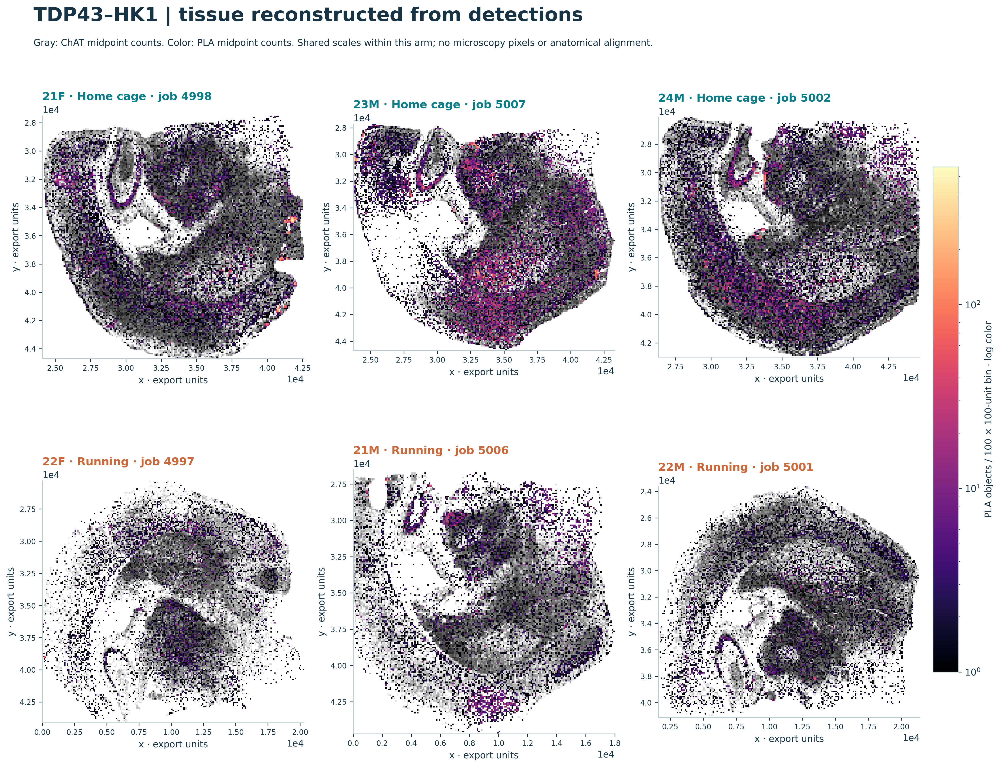

In [20]:
show(hp.native_atlas(fine, metadata, 'TDP43–HK1'), '02_native_overlay_hk1')

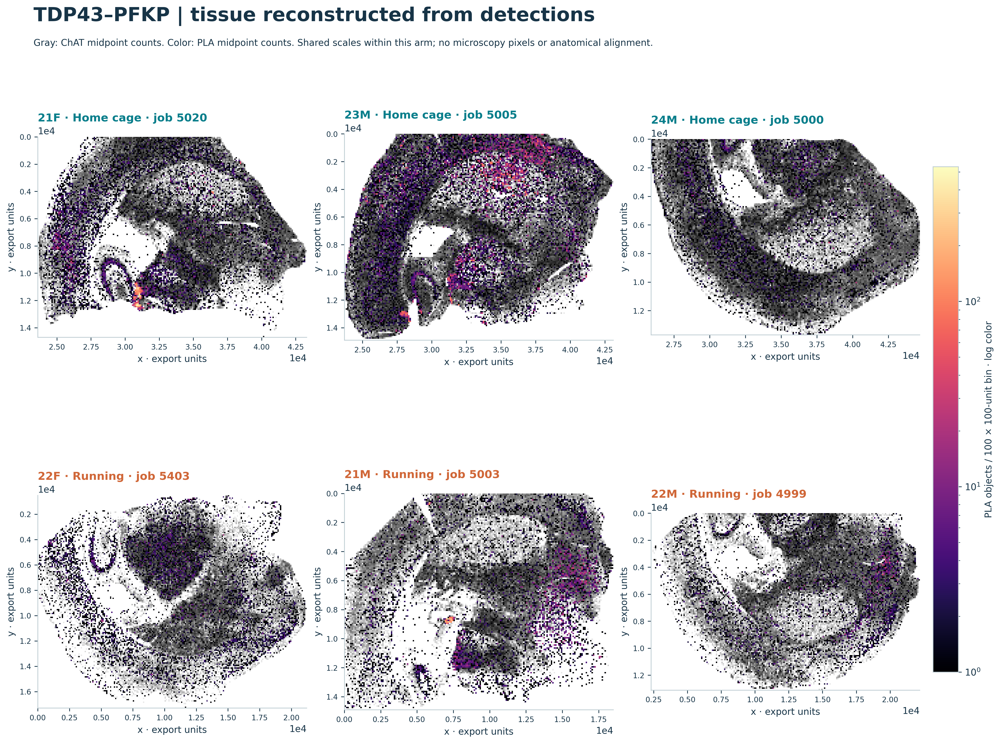

In [21]:
show(hp.native_atlas(fine, metadata, 'TDP43–PFKP'), '02_native_overlay_pfkp')

<a id="registration"></a>
## 4 · Registration review comes before anatomical comparison

The handoff prescribes a traced ventricular cavity, a geometric polygon centroid, a reviewed choice of **none / horizontal / vertical / both flips**, then translation to the cavity center. It prohibits fitting continuous rotations, rescaling or warping to improve agreement. A landmark-centered coordinate system preserves shape but cannot make different section levels anatomically equivalent. [Handoff, pp. 4–9](HALO_spatial_analysis_raw_data_handoff.pdf).

**First-pass proposal method:** use the union of all PLA and ChAT detections on a 250-unit grid; close occupied bins with two iterations of a 3×3 cross; identify enclosed holes; trace the largest hole if it covers at least six bins. This uses overall geometry, not a ChAT-positive subset or a Running-effect hotspot. It is a reproducible *proposal generator*, not a validated ventricular detector. Closing can fragment, shrink or bridge gaps. The polygon is traced around the resulting component and its area centroid is calculated by the shoelace formula.

**Current status:** none of the sections has a signed-off anatomical trace, orientation, scale or tissue mask. The legacy automatic previews below retain `none` as an unapproved flip choice and preserve their three missing candidates. The newer feature-aligned proposals above are separate and include all 12 sections. Review each polygon against the native data, especially the complex left-side void in 23M/HK1; several traces cover only part of the visible cavity. Do not advance these proposals automatically.

In [22]:
table(status, 'registration_gate')

,job,animal_id,pla_arm,candidate_found,ready,needs_review
0,4998,21F,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
1,5006,21M,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
2,4997,22F,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
3,5001,22M,TDP43–HK1,False,False,"ventricular trace, orientation, common scale, ..."
4,5007,23M,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
5,5002,24M,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
6,5020,21F,TDP43–PFKP,True,False,"ventricular trace, orientation, common scale, ..."
7,5003,21M,TDP43–PFKP,False,False,"ventricular trace, orientation, common scale, ..."
8,5403,22F,TDP43–PFKP,True,False,"ventricular trace, orientation, common scale, ..."
9,4999,22M,TDP43–PFKP,True,False,"ventricular trace, orientation, common scale, ..."


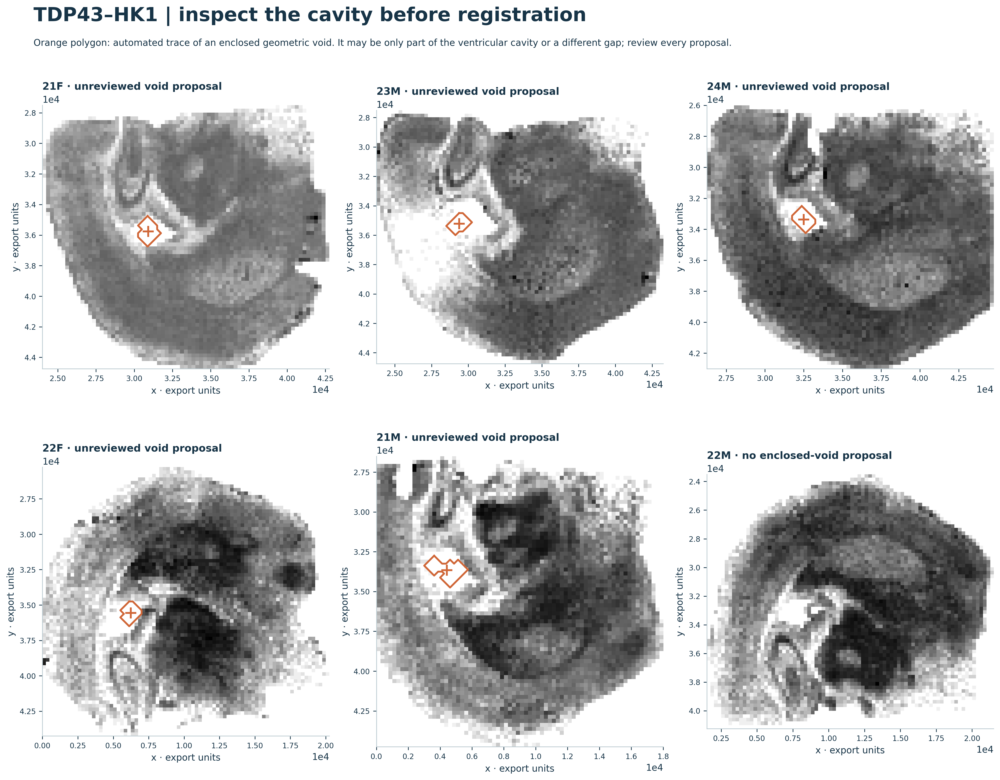

In [23]:
show(hp.landmark_atlas(geometry, reviews, 'TDP43–HK1'), '03_landmark_proposals_hk1')

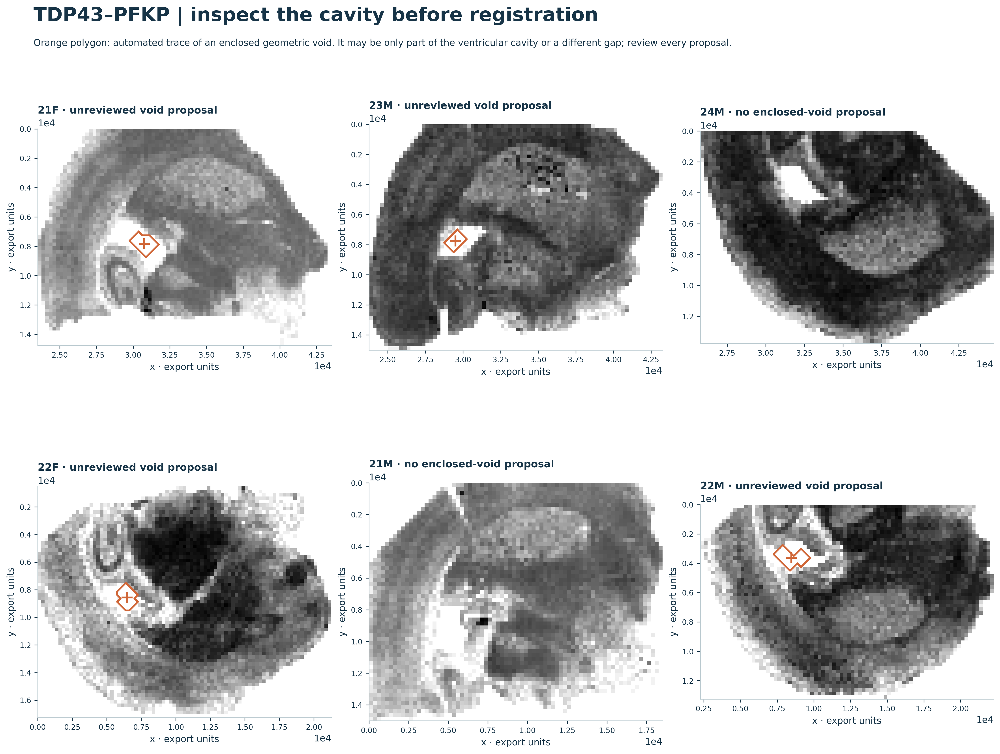

In [24]:
show(hp.landmark_atlas(geometry, reviews, 'TDP43–PFKP'), '03_landmark_proposals_pfkp')

### How the dimensions overlap after a proposed translation

The next two overlays answer a **geometry-review question**, not a biological one: how different are section silhouettes after placing their *candidate* centers at the origin? The orange/green/blue outlines identify animals; no contour is stretched to match another. Sections without a qualifying candidate are omitted and named beneath each figure. Morphological closing is used only to draw readable contours.

The handoff notes an expected straight cut edge. A straight edge, including one at coordinate zero, is **not automatically clipping**. All support labels remain uncertain until an image/ROI review can distinguish the expected cut from actual missing tissue.

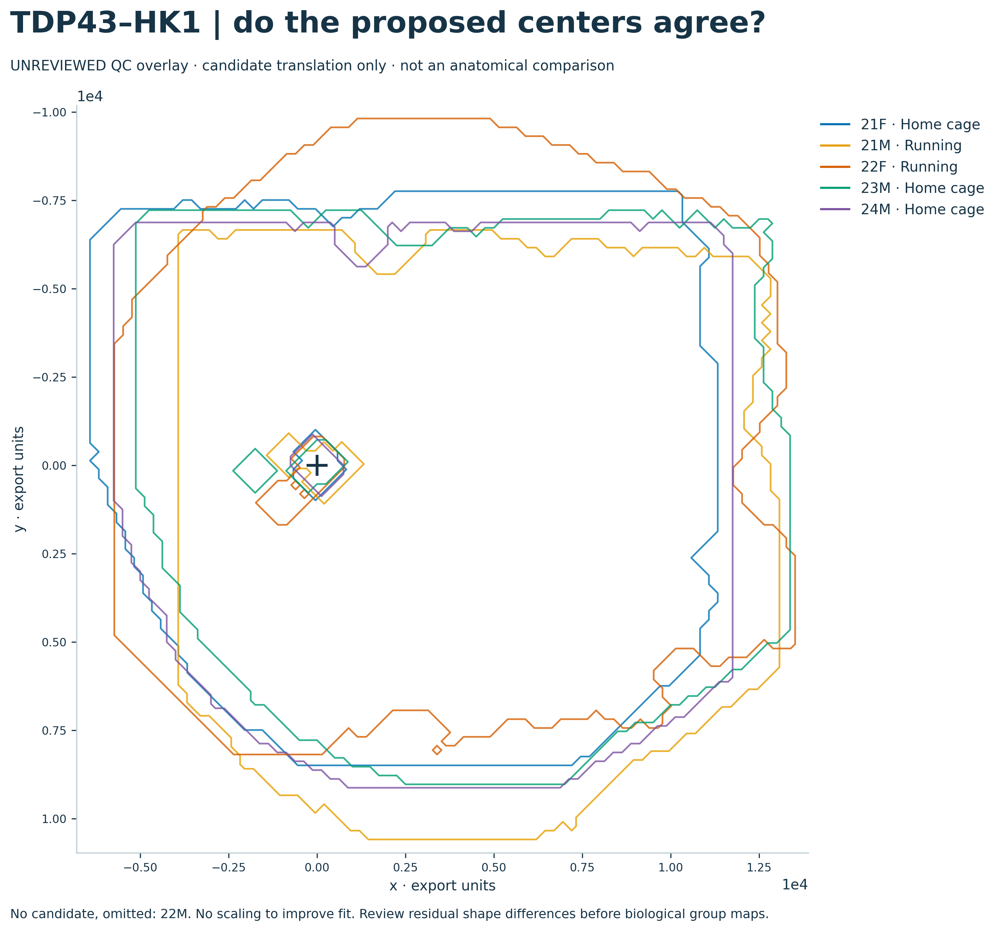

In [25]:
show(hp.silhouette_overlay(geometry, reviews, 'TDP43–HK1'), '04_candidate_outline_overlay_hk1')

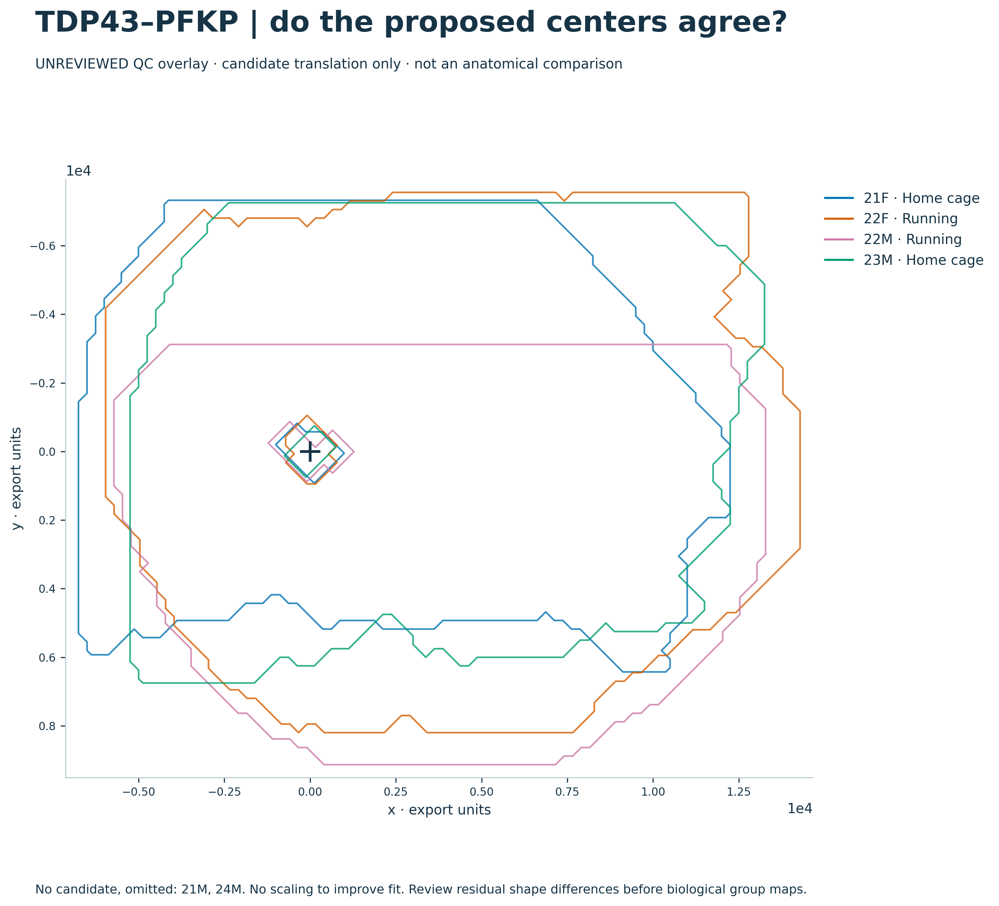

In [26]:
show(hp.silhouette_overlay(geometry, reviews, 'TDP43–PFKP'), '04_candidate_outline_overlay_pfkp')

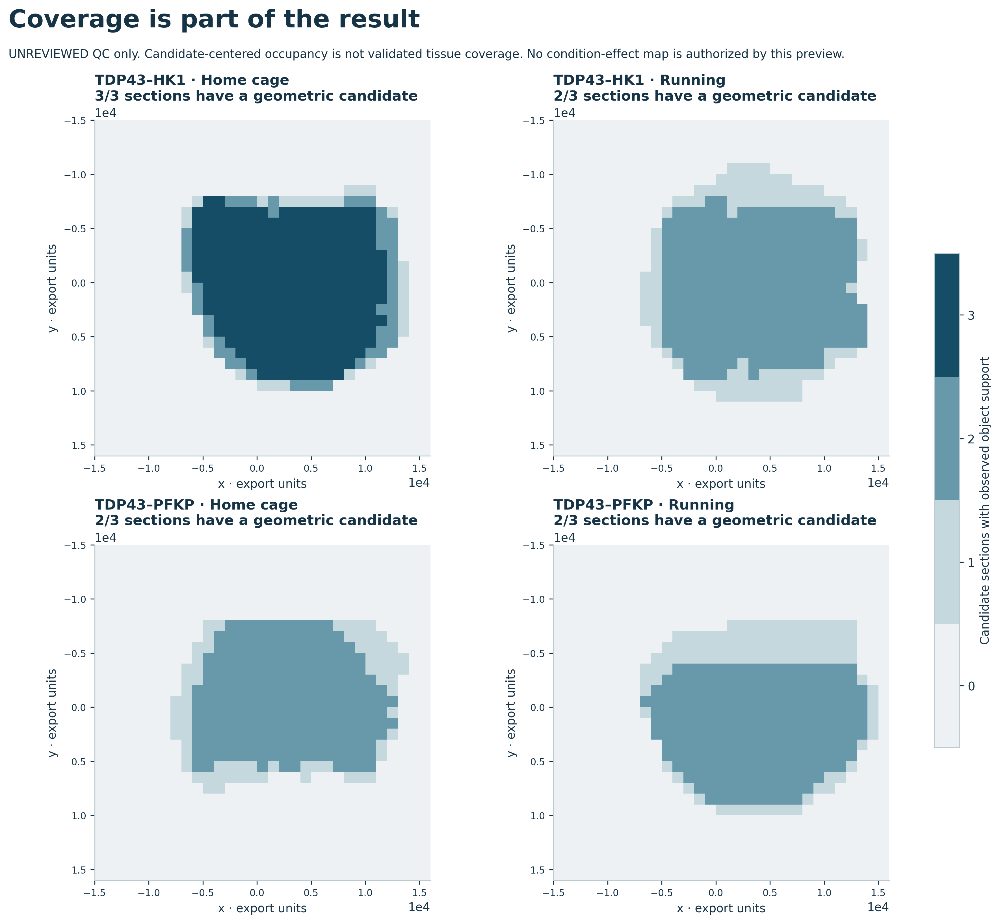

| Animal | PLA arm | Section QC | Flip review |
|---|---|---|---|
| 21F | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_4998.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_4998.png) |
| 21M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5006.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5006.png) |
| 22F | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_4997.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_4997.png) |
| 22M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5001.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5001.png) |
| 23M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5007.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5007.png) |
| 24M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5002.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5002.png) |
| 21F | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5020.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5020.png) |
| 21M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5003.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5003.png) |
| 22F | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5403.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5403.png) |
| 22M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_4999.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_4999.png) |
| 23M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5005.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5005.png) |
| 24M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5000.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5000.png) |

In [27]:
coverage = h.provisional_coverage(geometry, reviews)
show(hp.coverage_figure(coverage), '05_candidate_coverage')
# Save native/landmark/support and all four flip comparisons for every section.
qc_links = []
for r in reviews:
    job = r['job']
    for name, fig in [(f'qc_job_{job}', hp.qc_section(geometry[job], r)),
                      (f'flips_job_{job}', hp.flip_figure(geometry[job], r))]:
        hp.save(fig, OUT, name); plt.close(fig)
    qc_links.append(f'| {r["animal_id"]} | {r["pla_arm"]} | '
                    f'[Native / cavity / support](outputs/spatial_handoff/figures/qc_job_{job}.png) | '
                    f'[Four orientation choices](outputs/spatial_handoff/figures/flips_job_{job}.png) |')
display(Markdown('| Animal | PLA arm | Section QC | Flip review |\n|---|---|---|---|\n'+'\n'.join(qc_links)))

**Support is not tissue area.** Here, an occupied all-object geometry bin is provisional evidence of sampling. An empty bin is unknown, not a biological zero; a dense marker field can also hide a tear. True ROI polygons are preferred. The coverage figure counts candidate sections with observations and is labeled as QC because neither alignment nor coverage has passed review.

**Explicit first-pass exception:** the following native-coordinate marker maps and whole-section summaries are descriptive review products. They do not depend on a common anatomical origin. Registered Running-minus-Home biological maps, tissue-area densities and spatial enrichment tests remain withheld until the handoff's review gates pass. This exception permits inspection of the available data without turning unreviewed geometry into biological localization.

<a id="maps"></a>
## 5 · Heat maps with visible denominators

For each 1,000 × 1,000-export-unit bin, the association map is

**Association (%) = 100 × ChAT-positive PLA count / all PLA count in that bin.**

Show a value only with **at least 10 PLA objects**. Pale gray means other objects were observed but the PLA denominator is too small. White means no object support. A zero among sufficient PLA observations is a measured zero; a missing bin is NA. No smoothing, imputation or animal pooling is applied. The shared 0–100% scale makes fractions comparable as measurements, without implying anatomical correspondence.

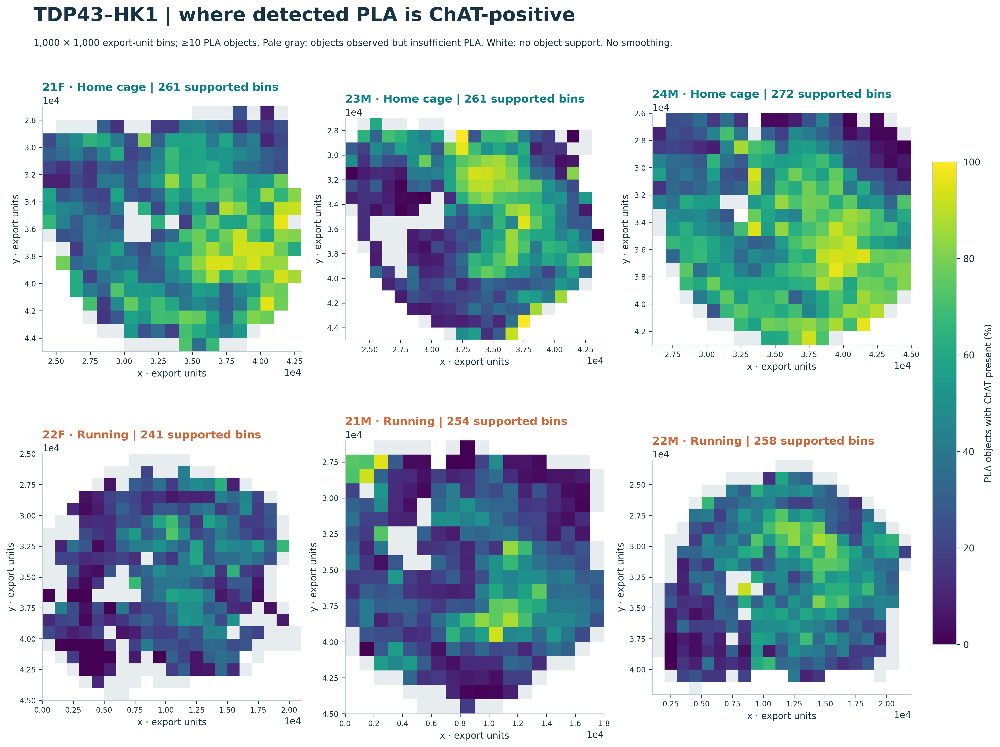

In [28]:
show(hp.fraction_atlas(metrics, metadata, 'TDP43–HK1'), '06_fraction_atlas_hk1')

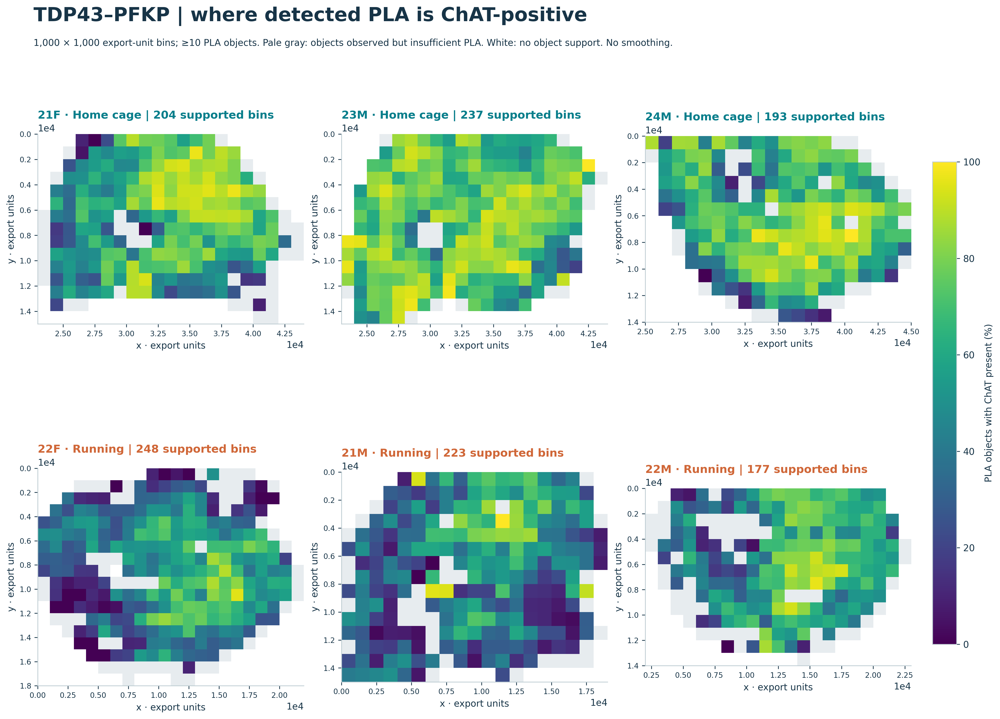

In [29]:
show(hp.fraction_atlas(metrics, metadata, 'TDP43–PFKP'), '06_fraction_atlas_pfkp')

### Zoom through every section

The left panel is the reconstructed overlay, the middle panel the supported ChAT-positive PLA fraction, and the right panel its PLA denominator. Move the slider to another animal. Wheel/pinch to zoom, drag to select a window, double-click to reset. Coordinates stay native, so reference them when requesting a microscopy review. The controls are embedded in the saved notebook; no web service or API is needed.

In [30]:
explorer_hk1 = hp.interactive_native(fine, metrics, metadata, 'TDP43–HK1')
explorer_hk1.show(config=PLOT_CONFIG)

In [31]:
explorer_pfkp = hp.interactive_native(fine, metrics, metadata, 'TDP43–PFKP')
explorer_pfkp.show(config=PLOT_CONFIG)

### Complementary readouts: a high fraction is only one part of the story

The six-panel views separate PLA detections, independent ChAT detections, association, **whole area of ChAT-positive PLA objects**, mean PLA size, and fraction of PLA at least 1 µm². The area of marker-positive PLA objects is different from the actual overlapping area. Both are exported. Sums of object areas can double-count overlapping objects and are not total tissue coverage.

The displayed 21F sections are a fixed example per arm, not selected for a condition effect. The same six-panel output is generated for **all 12 sections** in the figure directory. Large-area cutoffs are exploratory and fixed across animals, not biological aggregate definitions.

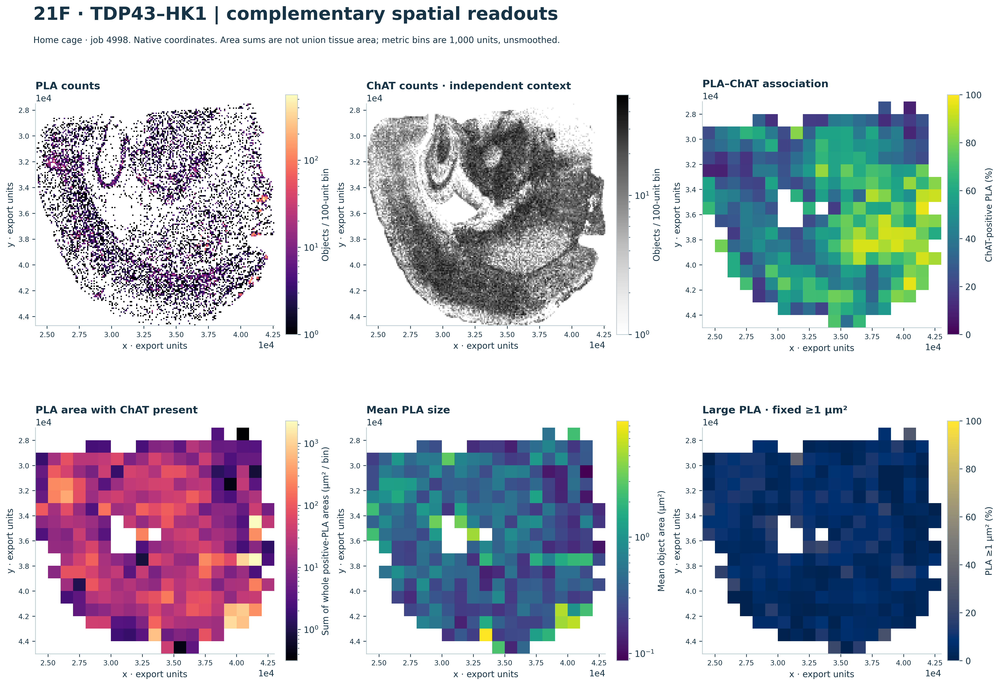

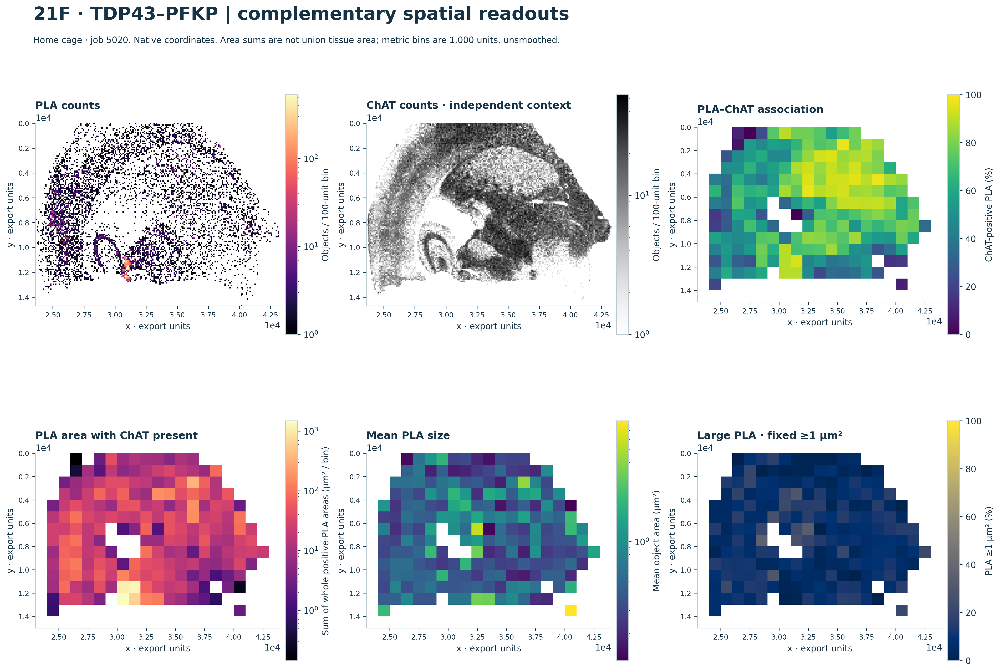

In [32]:
for row in metadata.itertuples():
    fig = hp.detailed_section(fine[str(row.job)], metrics[str(row.job)], row)
    saved = hp.save(fig, OUT, f'07_section_{row.job}_six_metrics')
    if row.animal_id == '21F': display(Image(filename=str(saved), embed=True, width=1100))
    plt.close(fig)

<a id="three-d"></a>
## 6 · Interactive 3D signal-height surfaces

**Rotate with the mouse, scroll/pinch to zoom, and use the section slider.** “Look down” returns to a plan view. Each arm has its own viewer. Hover reports raw PLA counts, ChAT counts and supported association. The height is **log(1 + PLA count per 500 × 500-unit bin)**, with tick labels showing counts. This exposes low-count structure without clipping extreme peaks; it is a display transform, not a statistical adjustment. The height/color scale is shared across animals within each arm.

The x:y aspect ratio preserves native section proportions. Height is deliberately a different unit. Surface facets connect neighboring bin centers only for display, with gaps where object support is absent. Native dimensions, heat-map pixels and exact bin counts remain available in the 2D views. There is **no measured z**, no assumed thickness and no interpolation between animals or PLA arms.

In [33]:
surface_hk1 = hp.interactive_surface(surfaces, metadata, 'TDP43–HK1')
surface_hk1.show(config=PLOT_CONFIG)

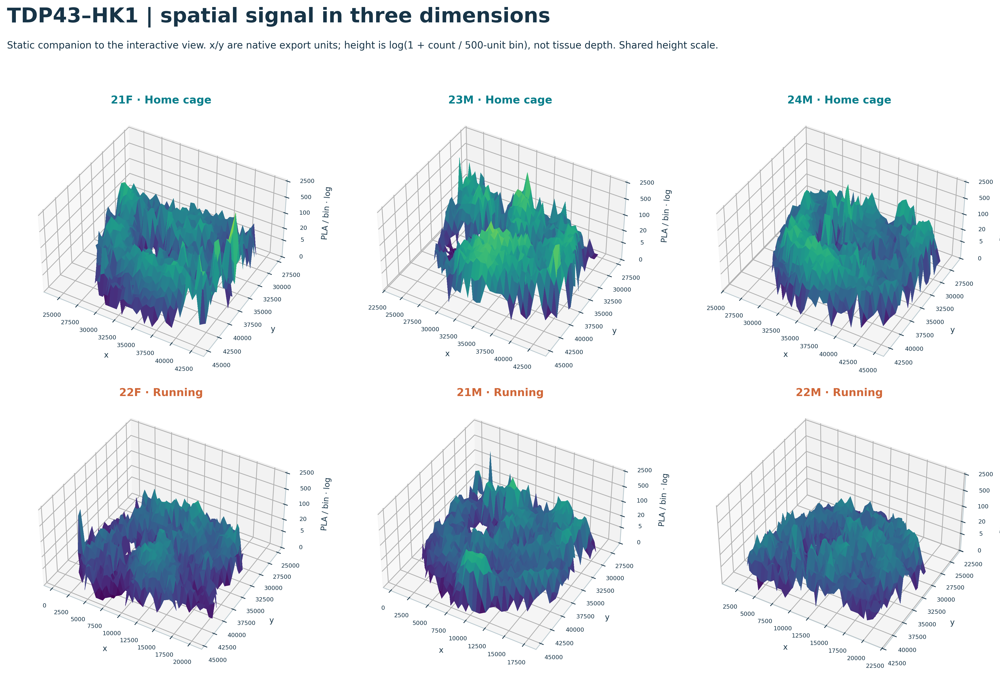

In [34]:
show(hp.surface_preview(surfaces, metadata, 'TDP43–HK1'), '08_surface_companion_hk1')

In [35]:
surface_pfkp = hp.interactive_surface(surfaces, metadata, 'TDP43–PFKP')
surface_pfkp.show(config=PLOT_CONFIG)

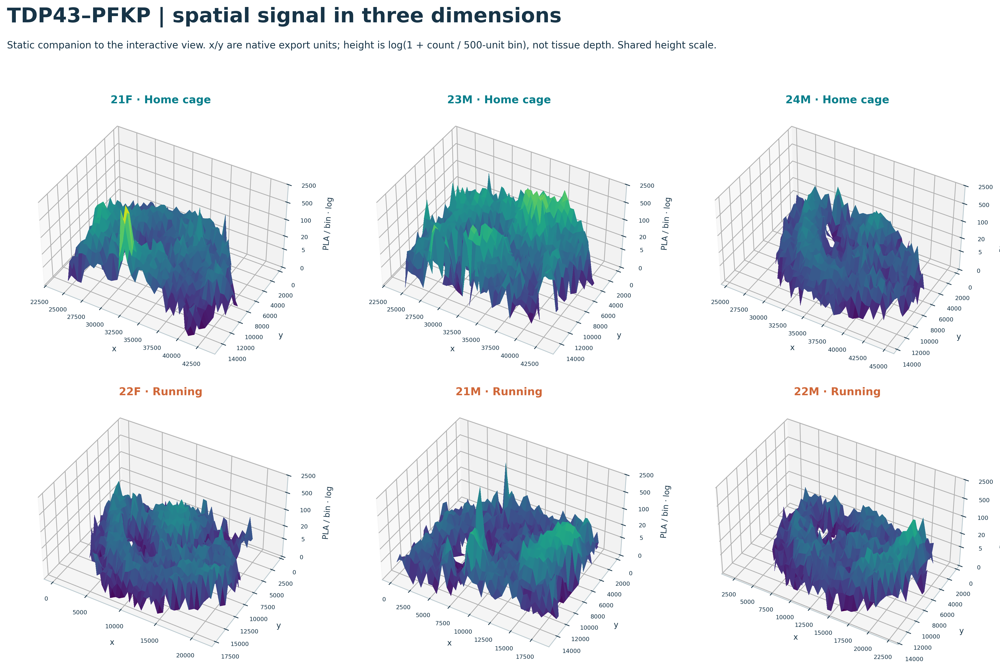

In [36]:
show(hp.surface_preview(surfaces, metadata, 'TDP43–PFKP'), '08_surface_companion_pfkp')

<a id="findings"></a>
## 7 · What changes at the animal level?

Whole-section summaries can be compared without claiming spatial registration. Each animal contributes one value **within each arm**, with equal weight. Detected puncta are nested measurements, not biological replicates. With three animals per condition, these are exploratory effect descriptions, not population-level confirmation. No cell-level or pixelwise p-values are fitted. [Lazic, 2010](https://pmc.ncbi.nlm.nih.gov/articles/PMC2817684/).

The left column asks what fraction of PLA is ChAT-positive. The middle column asks what fraction of PLA object area lies in those positive objects—**not** what fraction of tissue is colocalized. The right column shows independent ChAT detection counts, which help identify changes in marker opportunity or sampling. Counts are not normalized tissue density and are not neuron counts.

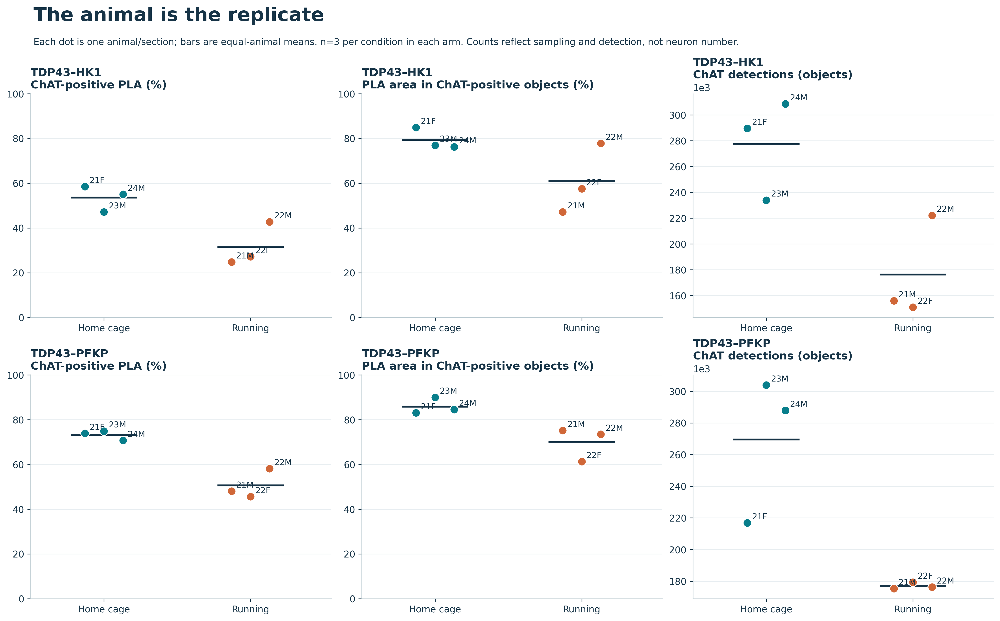

,pla_arm,metric,unit,home_mean,running_mean,home_minus_running,n_home,n_running,n_finite_home,n_finite_running,leave_pair_out_min,leave_pair_out_max
0,TDP43–HK1,association_pct,percentage points,53.586,31.580,22.006,3,3,3,3,16.156,30.798
7,TDP43–PFKP,association_pct,percentage points,73.203,50.618,22.585,3,3,3,3,19.219,27.593


**TDP43–HK1:** Home cage **53.59%**, Running **31.58%**; Home − Running **+22.01 percentage points**. Deleting one animal from each group in all nine combinations gives **16.16 to 30.80 points**. This is a sensitivity range, **not a confidence interval**.

**TDP43–PFKP:** Home cage **73.20%**, Running **50.62%**; Home − Running **+22.58 percentage points**. Deleting one animal from each group in all nine combinations gives **19.22 to 27.59 points**. This is a sensitivity range, **not a confidence interval**.

,animal_id,running_group,pla_arm,pla_objects,pla_with_chat,pla_association_pct,pla_total_area_um2,marker_positive_pla_area_um2,actual_overlap_area_um2,chat_objects
0,21F,Home cage,TDP43–HK1,33438,19574,58.538,"23,175.774","19,686.165","13,488.469",289644
1,21F,Home cage,TDP43–PFKP,23857,17639,73.936,"13,209.306","10,969.747","8,507.084",216845
2,22F,Running,TDP43–HK1,12644,3437,27.183,"8,438.703","4,855.773","2,012.327",150905
3,22F,Running,TDP43–PFKP,11589,5287,45.621,"7,160.049","4,389.130","2,035.998",179326
4,22M,Running,TDP43–HK1,14984,6402,42.726,"10,266.367","7,992.291","3,840.487",222160
5,22M,Running,TDP43–PFKP,8412,4893,58.167,"4,344.564","3,192.802","1,919.583",176272
6,24M,Home cage,TDP43–HK1,41237,22710,55.072,"21,662.494","16,525.121","9,348.140",308539
7,24M,Home cage,TDP43–PFKP,7733,5470,70.736,"4,627.052","3,913.245","2,344.615",287944
8,21M,Running,TDP43–HK1,20478,5085,24.832,"16,157.550","7,624.159","2,495.491",155945
9,21M,Running,TDP43–PFKP,18160,8729,48.067,"13,228.260","9,947.806","4,384.953",175392


In [37]:
show(hp.group_summary_figure(summary), '09_equal_animal_summary')
contrasts = condition_primary.copy()
table(contrasts, 'equal_animal_association_contrasts')
for r in contrasts.itertuples():
    display(Markdown(f'**{r.pla_arm}:** Home cage **{r.home_mean:.2f}%**, Running **{r.running_mean:.2f}%**; '
                     f'Home − Running **{r.home_minus_running:+.2f} percentage points**. '
                     f'Deleting one animal from each group in all nine combinations gives '
                     f'**{r.leave_pair_out_min:.2f} to {r.leave_pair_out_max:.2f} points**. '
                     'This is a sensitivity range, **not a confidence interval**.'))
table(summary[['animal_id','running_group','pla_arm','pla_objects','pla_with_chat','pla_association_pct',
               'pla_total_area_um2','marker_positive_pla_area_um2','actual_overlap_area_um2','chat_objects']],
      'animal_denominators_and_areas')

**Interpretation:** a lower Running-group fraction occurs in both independently analyzed arms. It describes the detected PLA–ChAT relationship in these six animals, not “less binding,” loss of cholinergic neurons, reduced glycolysis, or a causal running effect. ChAT object counts also differ, so lower marker opportunity, section geometry, detection thresholds or technical variation remain plausible contributors. The smaller size-specific gap in some bins does not eliminate those alternatives.

The leave-pair-out calculation checks whether removing any one animal in each condition reverses the descriptive direction. It does not measure the uncertainty of future animals. Specifying biological replicates, controls and an adequately sized follow-up experiment takes priority over fitting a more elaborate model to these same six animals.

### Size-dependent association and filter sensitivity

Fixed size bins are **[0, 0.03), [0.03, 0.1), [0.1, 0.3), [0.3, 1), [1, ∞) µm²**. The right column repeats the whole-section calculation after several minimum-area filters; each retained object is still counted once, and animals are still averaged equally. Thin curves show individuals so a group curve cannot hide one anomalous animal.

A rise with size can reflect increased geometric opportunity to overlap ChAT, merged detections, or genuine compartment association. This plot alone cannot distinguish those mechanisms. Use the exported size-bin denominators and microscopy controls before interpreting large PLA as complexes or aggregates.

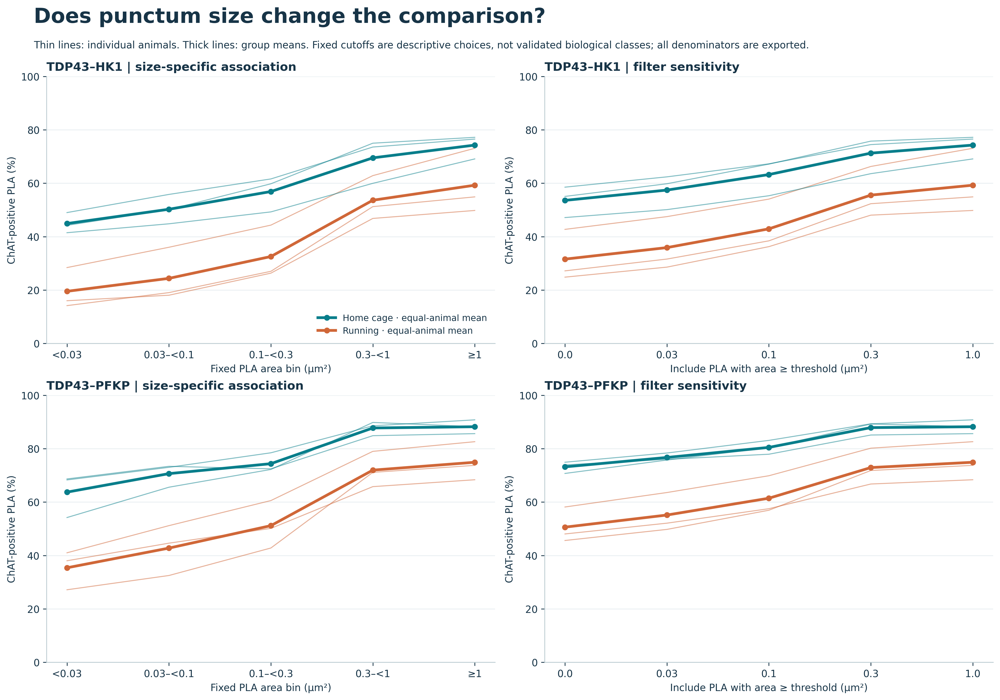

running_group         Home cage  Running
pla_arm    size_bin                     
TDP43–HK1  0.03–<0.1     50.261   24.373
           0.1–<0.3      56.895   32.552
           0.3–<1        69.515   53.640
           <0.03         44.906   19.524
           ≥1            74.291   59.267
TDP43–PFKP 0.03–<0.1     70.666   42.770
           0.1–<0.3      74.390   51.179
           0.3–<1        87.764   71.978
           <0.03         63.733   35.400
           ≥1            88.236   74.921

In [38]:
size_bins, sensitivity = h.size_tables(objects, metadata)
size_bins.to_csv(TABLES / 'size_bin_denominators.csv.gz', index=False, compression='gzip')
sensitivity.to_csv(TABLES / 'area_filter_sensitivity.csv.gz', index=False, compression='gzip')
show(hp.size_figure(size_bins, sensitivity), '10_size_and_filter_sensitivity')
size_means = size_bins.groupby(['pla_arm','running_group','size_bin'], observed=True).fraction_pct.mean().reset_index()
display(size_means.pivot(index=['pla_arm','size_bin'], columns='running_group', values='fraction_pct'))

## 8 · Nearest ChAT midpoint: a complementary spatial description

Compute the Euclidean distance from each PLA midpoint to the closest ChAT midpoint **in the same section** with a k-d tree. This is a center-to-center distance, not membrane distance, molecular separation or an alternative definition of HALO overlap. A large ChAT object can overlap PLA while their midpoints remain far apart.

Solid curves use all PLA. Dashed curves retain PLA with at least **500 export units** of conservative distance from unsampled support and whose nearest neighbor is closer than that boundary. Boundary clearance comes from the occupied 250-unit all-object grid, reduced by half the cell diagonal. Internal gaps count as boundaries; this intentionally conservative sensitivity analysis may exclude valid tissue and does not substitute for an ROI mask. Curves are per animal; x-axis display stops at the largest 99th percentile, while full quantile tables include the tail.

Distance units and support are unverified, so these curves are **within-section descriptive diagnostics**. They do not establish between-animal physical distance differences or attraction. A formal enrichment claim needs a tissue- and abundance-aware spatial null, not unrestricted random point placement or pixel shuffling. [Shivanandan et al., 2013](https://pubmed.ncbi.nlm.nih.gov/24299066/), [Dunn et al., 2011](https://pubmed.ncbi.nlm.nih.gov/21209361/).

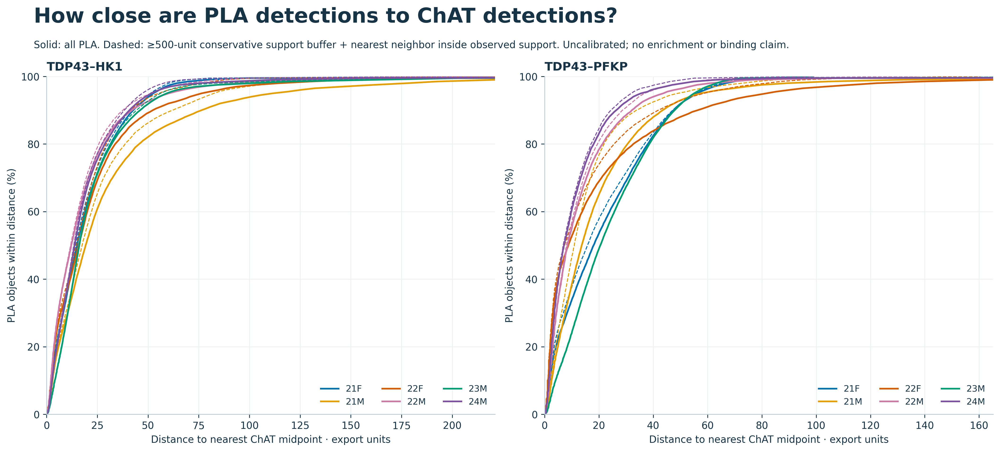

,job,n_pla,n_interior,retained_pct,median_all,median_interior,q95_all,animal_id,pla_arm,running_group
0,4997,12644,10780,85.258,15.890,14.705,76.449,22F,TDP43–HK1,Running
1,4998,33438,28690,85.801,15.008,14.422,52.559,21F,TDP43–HK1,Home cage
2,4999,8412,7700,91.536,8.500,8.062,43.718,22M,TDP43–PFKP,Running
3,5000,7733,6859,88.698,7.106,6.801,35.487,24M,TDP43–PFKP,Home cage
4,5001,14984,13416,89.536,12.104,11.853,60.253,22M,TDP43–HK1,Running
5,5002,41237,37885,91.871,13.757,13.463,51.620,24M,TDP43–HK1,Home cage
6,5003,18160,12786,70.407,13.657,10.966,57.489,21M,TDP43–PFKP,Running
7,5005,45123,39776,88.150,20.524,20.427,55.057,23M,TDP43–PFKP,Home cage
8,5006,20478,16429,80.228,19.235,17.500,111.553,21M,TDP43–HK1,Running
9,5007,72369,65106,89.964,16.101,16.101,59.237,23M,TDP43–HK1,Home cage


In [39]:
proximity_curves, proximity_summary = h.proximity_analysis(objects, metadata, geometry,
                                                          PARAMETERS['edge_buffer_export_units'])
proximity_curves.to_csv(TABLES / 'nearest_chat_quantile_curves.csv.gz', index=False, compression='gzip')
show(hp.proximity_figure(proximity_curves), '11_nearest_chat_distance')
table(proximity_summary, 'nearest_chat_summary')

<a id="actions"></a>
## 9 · Where the scientist should look next

The following review windows are chosen by **declared rules**: the highest PLA-count bin and the highest supported ChAT-positive fraction bin in each section. They are audit targets, not representative-field estimates or evidence of an anatomical hotspot. Coordinates are native, so the scientist can find the same windows in the original image. Ties use the first grid bin in row-major order; review both extreme and ordinary fields when validating segmentation.

,job,animal_id,pla_arm,reason,xmin,xmax,ymin,ymax,n_pla,n_chat,positive_pct
0,4998,21F,TDP43–HK1,largest PLA count,"41,000.000","42,000.000","34,000.000","35,000.000",3314,1474,90.585
1,4998,21F,TDP43–HK1,highest supported ChAT fraction,"41,000.000","42,000.000","35,000.000","36,000.000",1282,1270,96.490
2,5006,21M,TDP43–HK1,largest PLA count,"8,000.000","9,000.000","42,000.000","43,000.000",623,206,7.063
3,5006,21M,TDP43–HK1,highest supported ChAT fraction,"2,000.000","3,000.000","27,000.000","28,000.000",495,589,95.354
4,4997,22F,TDP43–HK1,largest PLA count,"11,000.000","12,000.000","29,000.000","30,000.000",207,1383,20.290
5,4997,22F,TDP43–HK1,highest supported ChAT fraction,"10,000.000","11,000.000","31,000.000","32,000.000",37,1467,72.973
6,5001,22M,TDP43–HK1,largest PLA count,"13,000.000","14,000.000","38,000.000","39,000.000",218,1297,42.661
7,5001,22M,TDP43–HK1,highest supported ChAT fraction,"8,000.000","9,000.000","33,000.000","34,000.000",61,231,91.803
8,5007,23M,TDP43–HK1,largest PLA count,"34,000.000","35,000.000","39,000.000","40,000.000",1712,491,76.402
9,5007,23M,TDP43–HK1,highest supported ChAT fraction,"32,000.000","33,000.000","28,000.000","29,000.000",24,12,100.000


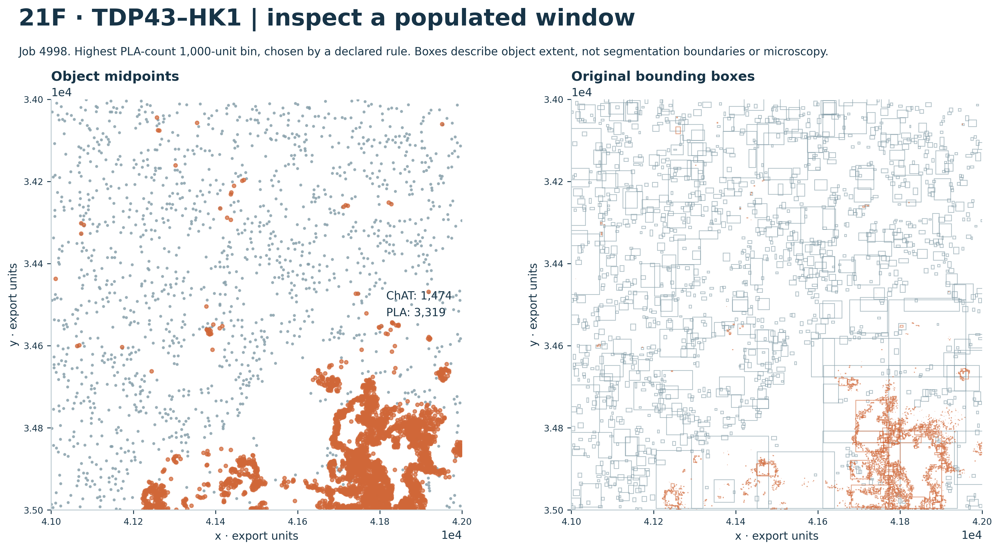

In [40]:
queue = h.spatial_review_queue(metrics, metadata)
table(queue.drop(columns='source_file'), 'image_review_windows')
queue.to_csv(TABLES / 'image_review_windows_with_sources.csv.gz', index=False, compression='gzip')
show(hp.zoom_boxes(objects, queue, '4998'), '12_midpoints_and_bounding_boxes')

### Actionable findings and decisions

| Observation / current limit | Next action | What it resolves |
|---|---|---|
| Raw and size-standardized gaps persist; every cross-animal and delete-one-per-group contrast is positive | Check ChAT segmentation and detection settings blinded to condition; use negative/single-antibody PLA controls and consistent acquisition | Whether detection opportunity or assay specificity explains the pattern |
| Condition coincides with low/high X image layout in all source images | Obtain original channels and composite provenance; audit illumination, background and thresholds across equivalent fields | Whether condition-aligned imaging or processing contributes to the gap |
| Larger PLA objects are more often ChAT-positive; extreme counts appear in localized windows | Review the coordinate queue plus ordinary fields in original channels; inspect merged objects and large-punctum boundaries | Whether size association reflects segmentation or compartment biology |
| ChAT detections vary across animals and conditions | Obtain HALO tissue ROI polygons and calibration; measure independent ChAT abundance per supported tissue area | Whether an apparent association shift accompanies a change in sampled marker opportunity |
| Nine enclosed-void proposals; three missing proposals; none approved | Manually trace full ventricular cavities, verify four-choice orientation, review expected cut edge and ambiguous cases with a second scientist | Whether an anatomical comparison is justified at all |
| No physical scale, z-stack or confirmed serial-section spacing | Supply original OME-TIFF/channel metadata, pixel size and section relationships | Calibrated image overlays; true 3D only if actual z/serial-section data exist |
| Only one marker panel and n=3 per condition | Plan additional animals, matched section levels, fixed analysis rules and other marker panels | Replication and cross-marker hypotheses without pseudoreplication |

### What the literature adds to the biological question

**HK1 deserves a distinct mechanistic hypothesis.** Barone and colleagues (2026) combined PLA with biochemical and metabolic assays in TDP-43/ALS systems, linking altered HK1 localization to impaired glycolysis. Their direct-binding conclusion used additional experiments; it cannot be transferred to our PLA maps. They also reported no TDP-43/PFK PLA in one mouse-model context. This motivates separate arm-specific assay controls here, rather than declaring this dataset's PFKP signal invalid. The present handoff does not establish an ALS genotype or the same experimental context. [Barone et al., 2026](https://pmc.ncbi.nlm.nih.gov/articles/PMC12992470/).

**Metabolic state is not read directly from a PLA count.** A different study found compensatory glycolysis changes in TDP-43 models, including PFK-related expression changes. That makes localization and functional metabolism complementary questions. A useful follow-up would pair the reviewed spatial result with an independently measured metabolic endpoint, appropriate to this experiment. [Manzo et al., 2019](https://elifesciences.org/articles/45114).

**A spatial null is a scientific model.** After mask and scale review, specify whether the null should preserve local ChAT abundance, PLA count, tissue compartment and spatial clustering. Consider within-section constrained shifts or block-based randomization with a predeclared distance statistic, then summarize the resulting effects per animal. Validate null behavior on known negative controls and simulated patterns; do not report a convenient shuffled-pixel p-value as evidence of interaction. No null-test or enrichment result is claimed in this notebook.

## 10 · Complete the registration review and unlock condition maps

The review records live in [metadata/handoff_section_reviews.json](metadata/handoff_section_reviews.json). Each record retains the source-file hash, geometric proposal, optional reviewed polygon, flip, scale/support flags, reviewer and notes. The initial records deliberately have **no approval flags set**.

To use the optional live editor, set `SHOW_REVIEW_EDITOR = True` in setup and run this cell. Edit vertices in **native export coordinates**, preview against the geometry, record the actual review and save the section. A confirmed horizontal/vertical flip needs a second reviewer. Ambiguous cavity or clipping cases also need independent review documented in the notes; leave them unapproved until resolved. The current support representation is a sampling proxy: accepting it does not create a physical tissue-area measurement. A different mask or calibration method requires a protocol revision.

Re-run the gate cell after changes. It computes condition maps only if all 12 sections pass the recorded requirements. Even then, use the coverage panels and equal-animal summaries; origin agreement alone does not establish section-level anatomical homology. This notebook does not silently exclude an uncertain animal to obtain a cleaner contrast.

In [41]:
if SHOW_REVIEW_EDITOR:
    display(hp.registration_widget(geometry, reviews, REVIEW_PATH))
else:
    print('Optional review editor disabled. All native maps, 3D viewers and findings above are available without it.')

Optional review editor disabled. All native maps, 3D viewers and findings above are available without it.


In [42]:
reviews = h.load_reviews(REVIEW_PATH, metadata, geometry)
status = h.review_status(reviews)
if status.ready.all():
    registered = h.registered_fraction_maps(objects, reviews, PARAMETERS['metric_bin'], PARAMETERS['min_pla_per_bin'])
    for arm, result in registered['arms'].items():
        fig, axes = plt.subplots(1, 5, figsize=(20, 5), layout='constrained')
        descriptions = [('Home cage', result['Home cage']['mean'], 'viridis', 0, 100),
                        ('Running', result['Running']['mean'], 'viridis', 0, 100),
                        ('Home − Running', -result['difference'], 'BrBG', -100, 100),
                        ('Home contributors', result['Home cage']['n'], 'viridis', 0, 3),
                        ('Running contributors', result['Running']['n'], 'viridis', 0, 3)]
        for ax, (name, z, cmap, lo, hi) in zip(axes, descriptions):
            im = hp.image(ax, registered, z, cmap, plt.Normalize(lo,hi))
            ax.set_title(name); fig.colorbar(im, ax=ax, shrink=.7); hp.coordinates(ax)
        hp.title(fig, arm+' | reviewed equal-animal maps', 'Fraction maps require three animals per group in each bin; NA is never zero.')
        show(fig, 'reviewed_group_'+arm.replace('–','_'))
else:
    display(Markdown(f'**Spatial group maps withheld: {status.ready.sum()}/12 sections pass review.** '
                     'Native descriptive maps and whole-section animal comparisons above remain available. '
                     'The missing requirements are listed below.'))
    display(status[['animal_id','pla_arm','ready','needs_review']])

**Spatial group maps withheld: 0/12 sections pass review.** Native descriptive maps and whole-section animal comparisons above remain available. The missing requirements are listed below.

,animal_id,pla_arm,ready,needs_review
0,21F,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
1,21M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
2,22F,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
3,22M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
4,23M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
5,24M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
6,21F,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."
7,21M,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."
8,22F,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."
9,22M,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."


## 11 · Reproducibility and a practical handoff

All core results are embedded in this notebook. Supplementary outputs live in `outputs/spatial_handoff/`: 300-DPI PNG/SVG figures, compressed tables, lossless grid arrays and a versioned protocol snapshot. The raw CSVs remain unchanged. `latest_protocol.txt` identifies the matching snapshot; prior content-addressed snapshots are retained. When changing a scientific rule, increment the protocol version and record the reason in the code/commit as well as producing a new snapshot.

`EXPORT_OBJECT_TABLES = True` additionally writes a large per-section object table with the native box coordinates, source file, object ID, animal/arm and coordinate-transformation fields. Aligned fields remain NA until the section passes review. The compact default preserves object provenance through the original CSV + manifest and recomputes from raw data on every Run All.

**Methods not claimed as completed:** true microscopy-image overlay, anatomical volume reconstruction, calibrated tissue-area density, validated ventricular registration, spatial enrichment, cross-marker PCA and confirmed causal running effects. The supplied data do not establish those results. The notebook supplies the native views, review tools, animal-level analyses and exact inputs needed to progress toward them.

In [43]:
app_path = write_standalone_app(explorer_html(fine, geometry, surfaces, metrics, metadata, reviews, include_plotly=False, proposals=alignment_proposals), ROOT,
                                comparison_fragment=cv.comparison_html(condition_results, registration=cc.condition_registration(objects, reviews, PARAMETERS['metric_bin'], PARAMETERS['min_pla_per_bin'])),
                                ml_fragment=mv.explorer_html(ml_results, include_plotly=False))
display(Markdown(f'**Plotly app refreshed.** [Open the running app](http://127.0.0.1:8050/) · '
                 f'[Portable browser copy]({app_path.relative_to(ROOT).as_posix()}). '
                 'Start `Launch_Spatial_Explorer.command` or `python scripts/serve_spatial_app.py` for the local link. '
                 'The app contains this run’s saved measurements and scientific figures.'))

**Plotly app refreshed.** [Open the running app](http://127.0.0.1:8050/) · [Portable browser copy](outputs/spatial_handoff/app/index.html). Start `Launch_Spatial_Explorer.command` or `python scripts/serve_spatial_app.py` for the local link. The app contains this run’s saved measurements and scientific figures.

In [44]:
if EXPORT_OBJECT_TABLES:
    h.export_objects(objects, metadata, reviews, OUT / 'object_tables')
protocol_path = h.write_protocol(ROOT, OUT, manifest, reviews, PARAMETERS)
print('Protocol:', protocol_path.relative_to(ROOT))
print('Figures:', len(list((OUT / 'figures').glob('*.png'))), 'PNG files + SVG counterparts')
print('Tables:', len(list(TABLES.glob('*.csv.gz'))), '| Raw-file and code hashes retained.')
print('Analysis complete. Save this notebook to retain the current outputs.')

Protocol: outputs/spatial_handoff/protocols/v1.4.1_1061c0df7f19.json
Figures: 65 PNG files + SVG counterparts
Tables: 50 | Raw-file and code hashes retained.
Analysis complete. Save this notebook to retain the current outputs.


## Research and method decisions

The focused literature review covered PLA interpretation, TDP-43/metabolic mechanisms, nested-data statistics, microscopy colocalization, spatial point patterns, bioimage reporting and perceptual color. Searches included recent HK1/PFKP work and foundational methods. It is a targeted methods review, not a systematic evidence review. Primary publications and official software documentation were consulted on **18–19 October 2026**.

| Source | Decision implemented here |
|---|---|
| [Söderberg et al. (2006), *Direct observation of individual endogenous protein complexes in situ by proximity ligation*](https://www.nature.com/articles/nmeth947) | Explain PLA amplification/proximity; do not infer binding from these detections alone. |
| [Barone et al. (2026), *TDP-43 impairs glycolysis by sequestering hexokinase 1 in amyotrophic lateral sclerosis*](https://pmc.ncbi.nlm.nih.gov/articles/PMC12992470/) | Frame arm-specific mechanistic follow-up; separate the present descriptive result from disease-model/functional evidence. |
| [Manzo et al. (2019), *Glycolysis upregulation is neuroprotective as a compensatory mechanism in ALS*](https://elifesciences.org/articles/45114) | Treat metabolic function as a separate endpoint requiring direct measurement. |
| [Ho et al. (2019), *Moving beyond P values: data analysis with estimation graphics*](https://pubmed.ncbi.nlm.nih.gov/31217592/) | Show animal observations and effect magnitudes; sensitivity ranges are not confidence intervals. |
| [SciPy, permutation_test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html) | Enumerate all 20 three-versus-three allocations as a design diagnostic under an explicitly unverified exchangeability assumption. |
| [Lazic (2010), *The problem of pseudoreplication in neuroscientific studies*](https://pmc.ncbi.nlm.nih.gov/articles/PMC2817684/) | Animal-level replication and equal weighting; no punctum-level treatment significance. |
| [Dunn, Kamocka & McDonald (2011), *A practical guide to evaluating colocalization in biological microscopy*](https://pubmed.ncbi.nlm.nih.gov/21209361/) | Distinguish co-occurrence metrics, show independent marker abundance, avoid misleading blended colors and naive spatial randomization. |
| [Shivanandan, Radenovic & Sbalzarini (2013), *MosaicIA*](https://pubmed.ncbi.nlm.nih.gov/24299066/) | Describe nearest-center distances with geometric context; reserve interaction/enrichment claims for a validated null. No MosaicIA model is fitted here. |
| [Crameri, Shephard & Heron (2020), *The misuse of colour in science communication*](https://www.nature.com/articles/s41467-020-19160-7) | Sequential perceptual maps, explicit shared scales, centered diverging color only for future signed differences. |
| [Schmied et al. (2023), *Community-developed checklists for publishing images and image analyses*](https://www.nature.com/articles/s41592-023-01987-9) | Label derived reconstructions and units, retain original data, export reproducible annotated figures and analysis code. |
| [Sarkans et al. (2021), *REMBI: Recommended Metadata for Biological Images*](https://www.nature.com/articles/s41592-021-01166-8) | Keep sample/image/analysis identities separate; request calibration, acquisition and experimental metadata. |
| [Plotly renderers](https://plotly.com/python/renderers/) and [configuration](https://plotly.com/python/configuration-options/) | Embedded notebook exploration with offline JS, wheel zoom, hover, sliders and static companions. |

Project-specific assignments and spatial constraints come from the **local handoff PDF (pp. 1–12)**, not from the papers. The computational measurements come from the raw CSVs listed with hashes in the manifest. Candidate geometric landmarks and plotting parameters are analysis choices, clearly labeled for review.